# NUDET project: vessel cylindrical shell with liner under gamma heating

**057922 Nuclear Design and Technology** · Part 1 (items 3 to 9), Part 2, Part 3

This notebook follows the structure of the instructor's G3 and G4 notebooks, applied to **our** data (Table 1 of the assignment).

**Conventions**
- Temperatures in **K** in the calculations, displayed in **°C** for the ASME checks.
- Radii: $R_w$ = wetted surface (liner inner face), $R_i$ = vessel inner face (liner/vessel interface), $R_o$ = vessel outer face, $R_2$ = insulation outer face.
- The **reference** is the **cylindrical** solver (same geometry as Z3ST); the **slab** solver is the hand check suggested by the assignment.
- Stress-free reference state: isothermal at the coolant temperature, $T_{ref} = T_{pr}$ (as the `T_ref` of the Z3ST material cards).

**Main modelling choices**
- Level A: in normal operation the vessel is in **hydrostatic compression** ($p$ on both sides), so the pressure gives **no** stress intensity.
- Stresses computed with the **Table 1** data ($E$ = 177 GPa, $\alpha$ = 1.54·10⁻⁵ K⁻¹ for the vessel; $E$ = 172 GPa, $\alpha$ = 1.93·10⁻⁵ K⁻¹ for the liner).
- External design pressure **7.55 MPa** (Part 0); $B$ is interpolated in the tabulated values of CS-5 ($B$ = 129.5 MPa at 150 mm and 292 °C).
- CS-5: the highest curve is at **345 °C** (not 370).
- Liner (NB-3122): kept in the **thermal** analysis because it is conservative; **no structural strength** attributed to it for the primary stresses (NB-3122.1); in the secondary and peak stresses it is modelled **bonded** to the vessel (two-layer cylinder, generalised plane strain), and the stress from the **differential expansion** liner/vessel is a **peak stress F** (Table NB-3217-1, NB-3213.11): it enters the fatigue evaluation only. Since the liner is ≤ 10 % of the thickness, NB-3122.3 exempts it from the $3S_m$ check.
- Slab vs cylinder: the slab is about 1 K warmer (slightly conservative); the design temperature comes from the cylindrical solver (or Z3ST).
- Item 9: the Fig. 2 formula and the linearised calculation are reconciled (adiabatic total peak vs linearised $P+Q$).
- Part 3: the build-up factor 1.4 is already in $q_0'''$ and is not applied again in the shield; the shield is sized on the mean vessel temperature ≤ 345 °C.
- No cell overwrites the global variables (`h1`, `U2`, `q0`, ...).

**Outline**
0. Data · 1. Tools · 2. Classification, design pressure, tentative thickness · 3. Item 4 · 4. Item 5 · 5. Item 6 (+ Z3ST) · 6. Item 7 · 7. Item 8 · 8. Item 9 · 9. Part 2 · 10. Part 3

---
## 0. Data (Table 1 of the assignment)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- Geometry -------------------------------------------------------------------
L       = 7.0        # m   length of the cylindrical shell
D_be    = 2.5        # m   barrel outer diameter
D_li    = 3.0        # m   wetted-surface diameter (liner inner face)
t_lin   = 5e-3       # m   liner thickness
t_ins   = 50e-3      # m   insulation thickness
k_ins   = 1.4        # W/(m K) insulation conductivity
h_head  = 1.5        # m   head depth (for the unsupported length, NB-3133.2)

R_w = D_li/2         # m   wetted surface = 1.500 m
R_i = R_w + t_lin    # m   vessel inner face = 1.505 m

# --- Primary fluid (pr) ---------------------------------------------------------
T_pr    = 487.15     # K   core inlet temperature (214 °C)
p_op    = 7.5e6      # Pa  operating pressure
m_dot   = 3227.0     # kg/s mass flow rate
cp_pr   = 4534.0     # J/(kg K)
rho_pr  = 852.5      # kg/m3
eta_pr  = 1.259e-4   # Pa s
k_pr    = 0.658      # W/(m K)

# --- Containment (CPP) water -----------------------------------------------------
T_cpp   = 343.15     # K   (70 °C)
cp_cpp  = 4172.5     # J/(kg K)
rho_cpp = 981.2      # kg/m3
eta_cpp = 4.06e-4    # Pa s
k_cpp   = 0.666      # W/(m K)
beta_cpp = 5.57e-4   # 1/K
g       = 9.81       # m/s2

# --- Austenitic liner, SA-240 Type 304L ------------------------------------------
k_aus     = 20.1     # W/(m K)
mu_aus    = 24.0     # 1/m  gamma attenuation
E_aus, nu_aus, alpha_aus, rho_aus = 172e9, 0.31, 1.93e-5, 8030.0
T_lim_aus = 425.0    # °C  material temperature limit (= 698.15 K)

# --- Ferritic vessel, SA-533 Gr. B Cl. 1 ------------------------------------------
k_fer     = 37.8     # W/(m K)
mu_fer    = 24.0     # 1/m  same attenuation as the liner
E_fer, nu_fer, alpha_fer, rho_fer = 177e9, 0.30, 1.54e-5, 7750.0
T_lim_fer = 370.0    # °C  material temperature limit (= 643.15 K)

# --- Gamma source ----------------------------------------------------------------
flux    = 1.5e17     # photons/(m2 s)  -- in m^-2, not cm^-2
E_gamma = 6.0        # MeV
B_bu    = 1.4        # build-up factor  (do NOT call it B: clash with the CS-5 chart factor)
MeV     = 1.602e-13  # J/MeV

C2K = 273.15

---
## 1. Tools

**Slab solver** (check). 1D finite differences of $-\frac{d}{dx}\left(k\frac{dT}{dx}\right) = q'''(x)$ across liner + vessel, $k$ at mid-points (continuous flux at the interface), Robin conditions on both sides:

$$-k\,T'(0) = h_1\,(T_{pr} - T(0)), \qquad k\,T'(t_L + t) = U_2\,(T_{cpp} - T(t_L+t))$$

**Cylindrical solver** (reference, as Z3ST). Finite volumes of $\frac{1}{r}\frac{d}{dr}\left(k\,r\frac{dT}{dr}\right) + q'''(r) = 0$, layers stacked from the wetted surface, cylindrical source profile $q'''(r) = q_0'''\,K_0(\mu r)/K_0(\mu R_w)$ as in Z3ST (item 5). $h$ at the inner face, $U_2$ referred to $R_o$ at the outer face.

**Mean through the thickness** (NCA-2142.1(b), *mean metal temperature*), on the vessel only:
$\bar T = \dfrac{\int_{R_i}^{R_o} T\,r\,dr}{\int_{R_i}^{R_o} r\,dr}$.

**Stresses** (hollow cylinder $a$–$b$, NB-3122.3: liner neglected since $\le 10\,\%$ of the thickness):
- thermal, free ends (Timoshenko);
- Lamé with internal pressure $p_i$ **and** external pressure $p_e$, closed ends;
- linearisation through the thickness: membrane + bending → $P_m$ (pressure only) and $P_m+P_b+Q$; the maximum point value gives the total peak ($+F$).

In [ ]:
from scipy.linalg import solve_banded
from scipy.optimize import brentq
import pandas as pd
from scipy.special import k0e      # k0e(z) = K0(z)·e^z, avoids underflows (mu r ≈ 36)

c = lambda T: T - C2K          # K -> °C


# =============================================================================================
# _tridiag(lo, di, up, b)
# ---------------------------------------------------------------------------------------------
# Solves A x = b for a TRIDIAGONAL matrix A, given by its three diagonals.
#
# Inputs
#   lo : (n-1,) sub-diagonal,   lo[j] = A[j+1, j]
#   di : (n,)   main diagonal,  di[j] = A[j, j]
#   up : (n-1,) super-diagonal, up[j] = A[j, j+1]
#   b  : (n,)   right-hand side
# Output
#   x  : (n,)   solution
#
# How: scipy's solve_banded wants the "banded" storage ab[u + i - j, j] = A[i, j] (u = l = 1):
#   row 0 = super-diagonal shifted right, row 1 = diagonal, row 2 = sub-diagonal shifted left.
#   Banded LU (LAPACK gbsv, partial pivoting): O(n) instead of O(n^3) for a full matrix.
# =============================================================================================
def _tridiag(lo, di, up, b):
    ab = np.zeros((3, len(di)))
    ab[0, 1:] = up            # A[j-1, j]: ab[0, 0] is unused
    ab[1] = di                # A[j, j]
    ab[2, :-1] = lo           # A[j+1, j]: ab[2, n-1] is unused
    return solve_banded((1, 1), ab, b)


# ---------------- slab (hand check) -------------------------------------------------------

# =============================================================================================
# solve_wall(t_v, t_L, q0, h1, U2, ...)
# ---------------------------------------------------------------------------------------------
# 1D steady conduction in a SLAB (curvature neglected): liner [0, t_L] + vessel [t_L, t_L + t_v],
#   d/dx(k dT/dx) + q(x) = 0, with a gamma source attenuated exponentially from the wetted face.
#
# Inputs
#   t_v, t_L    : vessel and liner thicknesses (m)  (t_L = 0: vessel without liner)
#   q0          : volumetric gamma source at the wetted face x = 0 (W/m3)
#   h1, U2      : heat transfer coefficients, inner (primary) and outer (insulation + CPP) (W/m2K)
#   mu, mu_L    : attenuation coefficients, vessel and liner (1/m)
#   k_v, k_L    : conductivities, vessel and liner (W/mK)
#   T_in, T_out : fluid temperatures, primary and CPP (K)
#   dx_target   : target mesh step (m)
# Outputs
#   x : (m,) node positions from the wetted face (m)
#   T : (m,) nodal temperatures (K)
#   N : index of the node at the liner/vessel interface
#
# Method: finite differences, k evaluated at mid-points (flux continuous at the interface),
#   Robin conditions on both faces (first order), tridiagonal system.
# =============================================================================================
def solve_wall(t_v, t_L, q0, h1, U2, mu=mu_fer, mu_L=mu_aus, k_v=k_fer, k_L=k_aus,
               T_in=T_pr, T_out=T_cpp, dx_target=1e-4):
    N = int(round(t_L/dx_target)); M = int(round(t_v/dx_target)); m = N + M + 1   # nodes: liner N steps, vessel M steps
    x = np.linspace(0, t_L + t_v, m); dx = x[1] - x[0]                              # uniform grid, x[N] ≈ t_L
    # gamma source, continuous at the interface: e^(-mu_L x) in the liner, then e^(-mu (x - t_L)) in the vessel
    q = np.where(x <= t_L, q0*np.exp(-mu_L*x), q0*np.exp(-mu_L*t_L - mu*(x - t_L)))
    kh = np.where(0.5*(x[1:] + x[:-1]) < t_L, k_L, k_v)     # kh[j] = k_{j+1/2}, conductivity between nodes j and j+1
    lo, di, up, b = np.zeros(m-1), np.zeros(m), np.zeros(m-1), np.zeros(m)
    # interior node j: k_{j-1/2} T_{j-1} - (k_{j-1/2} + k_{j+1/2}) T_j + k_{j+1/2} T_{j+1} = -q_j dx^2
    lo[:m-2] = kh[:m-2]; up[1:] = kh[1:]
    di[1:-1] = -(kh[:-1] + kh[1:]); b[1:-1] = -q[1:-1]*dx**2
    # inner face: -k dT/dx = h1 (T_in - T_0)   ->   -(k/dx + h1) T_0 + (k/dx) T_1 = -h1 T_in
    di[0], up[0], b[0] = -(kh[0]/dx + h1), kh[0]/dx, -h1*T_in
    # outer face: -k dT/dx = U2 (T_m - T_out)  ->   -(k/dx) T_{m-2} + (k/dx + U2) T_{m-1} = U2 T_out
    lo[-1], di[-1], b[-1] = -kh[-1]/dx, kh[-1]/dx + U2, U2*T_out
    return x, _tridiag(lo, di, up, b), N


# =============================================================================================
# T_avg_vessel(x, T, N, t_L)
# ---------------------------------------------------------------------------------------------
# Mean metal temperature of the VESSEL only (nodes N to the end), weighted by r as in a
#   cylinder: T_avg = int T r dr / int r dr, with r = R_w + x (NCA-2142.1(b)).
# Inputs : x, T, N from solve_wall ; t_L (unused, kept for the call signature)
# Output : T_avg (K)
# =============================================================================================
def T_avg_vessel(x, T, N, t_L):
    r = R_w + x[N:]                                          # radius of the vessel nodes
    return np.trapezoid(T[N:]*r, r)/np.trapezoid(r, r)       # trapezoidal integrals


# =============================================================================================
# q_gen(q0, t_L, t_v, ...)
# ---------------------------------------------------------------------------------------------
# Heat generated per unit area in the slab (liner + vessel), analytic integral of q(x).
#   liner : int_0^tL q0 e^(-mu_L x) dx            = q0/mu_L (1 - e^(-mu_L t_L))
#   vessel: int q0 e^(-mu_L tL) e^(-mu(x-tL)) dx  = q0 e^(-mu_L t_L)/mu (1 - e^(-mu t_v))
# Output : W/m2. Used as an energy balance: it must equal the flux leaving both faces.
# =============================================================================================
def q_gen(q0, t_L, t_v, mu=mu_fer, mu_L=mu_aus):
    return q0/mu_L*(1 - np.exp(-mu_L*t_L)) + q0*np.exp(-mu_L*t_L)/mu*(1 - np.exp(-mu*t_v))


# =============================================================================================
# summary(x, T, N, t_L)
# ---------------------------------------------------------------------------------------------
# Key temperatures of a slab solution (all in K).
# Output dict: T_w   wetted face           T_i   liner/vessel interface
#              T_o   outer face            T_max vessel maximum
#              x_max position of T_max from the vessel inner face (m)
#              T_avg vessel mean (T_avg_vessel)
# =============================================================================================
def summary(x, T, N, t_L):
    Tv = T[N:]; i = int(np.argmax(Tv))                       # vessel nodes, index of the maximum
    return dict(T_w=T[0], T_i=T[N], T_o=T[-1], T_max=Tv[i], x_max=x[N:][i] - t_L,
                T_avg=T_avg_vessel(x, T, N, t_L))


# ---------------- cylindrical (reference) --------------------------------------------------

# =============================================================================================
# solve_cyl(R_a, layers, q0, h_in, h_out, ...)
# ---------------------------------------------------------------------------------------------
# 1D steady conduction in a multi-layer CYLINDER, finite volumes:
#   (1/r) d/dr(k r dT/dr) + q(r) = 0, gamma source with the cylindrical profile of Z3ST.
#
# Inputs
#   R_a         : inner radius of the first layer = wetted surface (m)
#   layers      : [(thickness, k, mu), ...] from R_a outwards (m, W/mK, 1/m)
#   q0          : volumetric gamma source at R_a (W/m3)
#   h_in        : coefficient on the inner face (W/m2K); 0 = adiabatic
#   h_out       : coefficient on the outer face, referred to the outer radius (W/m2K); 0 = adiabatic
#   T_in, T_out : fluid temperatures inside and outside (K)
#   n_per_mm    : cells per mm
# Output dict
#   rc, dr, r   : cell centres, cell widths, faces (m)
#   T           : cell-centre temperatures (K)
#   q           : source in each cell (W/m3)
#   q_in, q_out : flux densities through the inner / outer face (W/m2, > 0 = leaving the wall)
#   Ts_in/out   : surface temperatures (fluid + film drop), or the first/last cell if h = 0
#
# Method: one unknown per cell; heat balance of each cell = conduction through its two faces
#   (series resistances of the two half-cells, harmonic mean of k) + generation; tridiagonal.
# =============================================================================================
def solve_cyl(R_a, layers, q0, h_in, h_out, T_in=T_pr, T_out=T_cpp, n_per_mm=20):
    # --- mesh: faces rf, then per-cell conductivity and attenuation ---
    rf = [np.array([R_a])]; ks, mus = [], []
    for t, k, mu in layers:
        n = max(int(round(t*1e3*n_per_mm)), 1)                                     # cells in this layer
        rf.append(np.linspace(rf[-1][-1], rf[-1][-1] + t, n + 1)[1:]); ks += [k]*n; mus += [mu]*n
    r = np.concatenate(rf); rc = 0.5*(r[1:] + r[:-1]); dr = np.diff(r)              # faces, centres, widths
    k, mu_c = np.array(ks), np.array(mus)
    # --- source: optical depth tau at each cell centre (cumulated mu dr of the previous cells + half cell) ---
    tau = np.concatenate(([0.0], np.cumsum(mu_c*dr)))[:-1] + 0.5*mu_c*dr
    # q = q0 e^(-tau) k0e(mu r)/k0e(mu0 R_a); in one layer this is exactly q0 K0(mu r)/K0(mu R_a) (Z3ST):
    # e^(-tau) carries the attenuation layer by layer, k0e the slow geometric factor ~ sqrt(R_a/r)
    q = q0*np.exp(-tau)*k0e(mu_c*rc)/k0e(mu_c[0]*R_a)
    # --- conductances per radian and per metre: face radius / (resistances of the two half-cells) ---
    G = r[1:-1]/(dr[:-1]/(2*k[:-1]) + dr[1:]/(2*k[1:]))                            # between cell i and i+1
    G_in  = r[0]/(1/h_in + dr[0]/(2*k[0]))     if h_in  > 0 else 0.0                # fluid in -> first cell
    G_out = r[-1]/(1/h_out + dr[-1]/(2*k[-1])) if h_out > 0 else 0.0                # last cell -> fluid out
    # --- balance of cell i: -G_{i-1/2} T_{i-1} + (G_{i-1/2} + G_{i+1/2}) T_i - G_{i+1/2} T_{i+1} = q_i r_i dr_i ---
    di = np.zeros(len(rc)); di[:-1] += G; di[1:] += G; di[0] += G_in; di[-1] += G_out
    b = q*rc*dr; b[0] += G_in*T_in; b[-1] += G_out*T_out                            # fluid terms to the RHS
    T = _tridiag(-G, di, -G, b)                                                     # symmetric matrix
    # --- post-processing: flux densities at the faces (divide by the radius: W/(m rad) -> W/m2) ---
    q_in  = G_in*(T[0] - T_in)/r[0]
    q_out = G_out*(T[-1] - T_out)/r[-1]
    return dict(rc=rc, dr=dr, T=T, q=q, r=r, q_in=q_in, q_out=q_out,
                Ts_in=T_in + q_in/h_in if h_in > 0 else T[0],           # surface = fluid + film drop
                Ts_out=T_out + q_out/h_out if h_out > 0 else T[-1])


# =============================================================================================
# summary_cyl(sol, R_v)
# ---------------------------------------------------------------------------------------------
# Key temperatures of a cylindrical solution, the vessel being the cells with rc >= R_v.
# Inputs : sol from solve_cyl ; R_v vessel inner radius (= R_i with liner, = sol['r'][0] without)
# Output dict (K, m): T_w, T_i (interface: surface value if no liner, else interpolated),
#                     T_o, T_max, x_max (from R_v), T_avg (sum T r dr / sum r dr over the vessel)
# =============================================================================================
def summary_cyl(sol, R_v):
    rc, T, dr = sol['rc'], sol['T'], sol['dr']; v = rc >= R_v                       # vessel cells
    i = int(np.argmax(T[v]))
    T_i = sol['Ts_in'] if R_v <= sol['r'][0] + 1e-12 else np.interp(R_v, rc, T)     # no liner: wetted surface
    return dict(T_w=sol['Ts_in'], T_i=T_i, T_o=sol['Ts_out'], T_max=T[v][i], x_max=rc[v][i] - R_v,
                T_avg=np.sum(T[v]*rc[v]*dr[v])/np.sum(rc[v]*dr[v]))


# =============================================================================================
# wall_cyl(q0_w, h_w, liner=True, U=None)
# ---------------------------------------------------------------------------------------------
# Shortcut for solve_cyl on OUR wall (global t_lin, t_v, materials).
# Inputs : q0_w source at the wetted surface (W/m3) ; h_w inner coefficient (W/m2K)
#          liner : True = liner + vessel from R_w ; False = vessel alone from R_i (wetted)
#          U     : outer coefficient (default: global U2)
# Output : the solve_cyl dict
# =============================================================================================
def wall_cyl(q0_w, h_w, liner=True, U=None):
    U = U2 if U is None else U
    if liner:
        return solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (t_v, k_fer, mu_fer)], q0_w, h_w, U)
    return solve_cyl(R_i, [(t_v, k_fer, mu_fer)], q0_w, h_w, U)


# ---------------- stresses -------------------------------------------------------------------

# =============================================================================================
# stress_cyl(rc, T, dr, a, b, E, alpha, nu, p_in=0, p_out=0)
# ---------------------------------------------------------------------------------------------
# Stresses in ONE homogeneous hollow cylinder a-b: thermal (Timoshenko, generalised plane strain,
#   zero net axial force) + pressure (Lamé, closed ends), superposed.
#
# Inputs
#   rc, T, dr   : cell centres (m), temperatures (K), widths (m) of the cylinder cells only
#   a, b        : inner and outer radii (m)
#   E, alpha, nu: material
#   p_in, p_out : inner and outer pressures (Pa)
# Output
#   (s_r, s_t, s_z) : (n,) arrays of radial, hoop, axial stress at the cell centres (Pa)
#
# Notes: T may be absolute: a uniform temperature gives zero thermal stress.
#   alpha = 0 gives the pressure stresses only (primary).
# =============================================================================================
def stress_cyl(rc, T, dr, a, b, E, alpha, nu, p_in=0.0, p_out=0.0):
    Tr = T*rc*dr                              # T r dr of each cell
    Ir = np.cumsum(Tr) - 0.5*Tr               # int_a^rc T r dr, stopped at the cell centre
    Ib = Tr.sum()                             # int_a^b T r dr
    K = alpha*E/(1 - nu)
    # --- thermal (Timoshenko) ---
    s_r = K/rc**2*((rc**2 - a**2)/(b**2 - a**2)*Ib - Ir)
    s_t = K/rc**2*((rc**2 + a**2)/(b**2 - a**2)*Ib + Ir - T*rc**2)
    s_z = K*(2*Ib/(b**2 - a**2) - T)
    # --- pressure (Lamé): s_r = A0 - B0/r^2, s_t = A0 + B0/r^2, s_z = A0 (closed ends) ---
    A0 = (p_in*a**2 - p_out*b**2)/(b**2 - a**2)
    B0 = (p_in - p_out)*a**2*b**2/(b**2 - a**2)
    return s_r + A0 - B0/rc**2, s_t + A0 + B0/rc**2, s_z + A0


# =============================================================================================
# _SI(s)
# ---------------------------------------------------------------------------------------------
# Stress intensity (Tresca) = largest difference of principal stresses.
# Input : s = (s_r, s_t, s_z), principal since axisymmetric without shear
# Output: max(|s_r - s_t|, |s_t - s_z|, |s_r - s_z|)
# =============================================================================================
def _SI(s):
    return max(abs(s[0] - s[1]), abs(s[1] - s[2]), abs(s[0] - s[2]))


# =============================================================================================
# level_A(sol, a, b, E, alpha, nu, p_in, p_out)
# ---------------------------------------------------------------------------------------------
# ASME III Level A quantities for the VESSEL ALONE (liner given no strength, NB-3122.1).
#
# Inputs
#   sol          : solve_cyl dict (the cells with rc >= a are kept: vessel only)
#   a, b         : vessel inner and outer radii (m)
#   E, alpha, nu : vessel material
#   p_in, p_out  : pressures (Pa)
# Outputs (MPa)
#   Pm  : SI of the membrane stresses from the pressure only          -> Pm <= Sm
#   PQ  : SI of membrane +/- bending (linearised), pressure + thermal -> Pm + Pb + Q <= 3 Sm
#   tot : maximum point SI of the full stresses (P + Q + F)            -> fatigue
#
# Linearisation over t = b - a, x from mid-wall: membrane = (1/t) int s dx,
#   surface bending = (6/t^2) int s x dx.
# =============================================================================================
def level_A(sol, a, b, E, alpha, nu, p_in, p_out):
    v = sol['rc'] >= a - 1e-12; r, T, dr = sol['rc'][v], sol['T'][v], sol['dr'][v]   # vessel cells
    t = b - a; x = r - (a + b)/2                                                         # thickness, position from mid-wall
    def lin(sig):                                                                        # (membrane, surface bending)
        m = np.sum(sig*dr)/t; fb = 6/t**2*np.sum(sig*x*dr); return m, fb
    sP  = [lin(s) for s in stress_cyl(r, T, dr, a, b, E, 0.0,   nu, p_in, p_out)]       # pressure only (alpha = 0)
    sPQ = stress_cyl(r, T, dr, a, b, E, alpha, nu, p_in, p_out)                         # pressure + thermal
    L = [lin(s) for s in sPQ]
    Pm = _SI([m for m, _ in sP])                                                         # primary membrane
    PQ = max(_SI([m + sg*fb for m, fb in L]) for sg in (1, -1))                          # inner (+) and outer (-) surfaces
    tot = max(_SI([s[i] for s in sPQ]) for i in range(len(r)))                          # worst point, not linearised
    return Pm/1e6, PQ/1e6, tot/1e6


# =============================================================================================
# composite_cyl(sol, R_int, mats, p_in, p_out=0, T_ref=T_pr, closed=True)
# ---------------------------------------------------------------------------------------------
# Stresses in a TWO-LAYER cylinder (liner + vessel) BONDED at R_int, both layers structural,
#   generalised plane strain (same axial strain e0 in both layers). Same model as the reference
#   of the instructor's G5 case (checked on it: 427.38 / 543.24 MPa).
#
# Inputs
#   sol         : solve_cyl dict with the liner (from R_w) and the vessel
#   R_int       : liner/vessel interface radius (m), R_i
#   mats        : [(E, nu, alpha) liner, (E, nu, alpha) vessel]
#   p_in, p_out : pressures on the wetted face and on the outer face (Pa)
#   T_ref       : stress-free temperature (K), isothermal state at the coolant temperature
#   closed      : True = closed ends (axial force from the pressures on the end caps)
# Output dict
#   s_r, s_t, s_z : (n,) stresses at all cell centres, liner then vessel (Pa)
#   liner         : (n,) boolean mask of the liner cells
#
# Method: in each layer the radial displacement is the thermoelastic solution
#     u(r) = (1+nu)/(1-nu) alpha/r int_{r_start}^{r} (T - T_ref) r dr + C1 r + C2/r
#   5 unknowns (C1, C2 of the liner, C1, C2 of the vessel, e0), 5 conditions:
#     s_r = -p_in on the wetted face, s_r = -p_out on the outer face,
#     continuity of u and of s_r at the interface, axial force balance.
#   The conditions are linear in the unknowns: matrix built column by column, then solved.
# =============================================================================================
def composite_cyl(sol, R_int, mats, p_in, p_out=0.0, T_ref=T_pr, closed=True):
    rc, T, dr, r = sol['rc'], sol['T'], sol['dr'], sol['r']
    a, b = r[0], r[-1]                                        # wetted face, outer face
    masks = [rc < R_int, rc >= R_int]                         # liner cells, vessel cells

    # displacement and stresses in both layers for a given vector of unknowns x = [C1L, C2L, C1V, C2V, e0]
    def fields(x):
        out = []
        for j, (v, (E, nu, al)) in enumerate(zip(masks, mats)):
            rr, th, d = rc[v], T[v] - T_ref, dr[v]                # radii, temperature rise, widths of this layer
            I = np.cumsum(th*rr*d) - 0.5*th*rr*d                 # int_{r_start}^{r} (T - T_ref) r dr
            g = (1 + nu)/(1 - nu)*al
            C1, C2, e0 = x[2*j], x[2*j + 1], x[4]
            u  = g*I/rr + C1*rr + C2/rr                           # radial displacement
            du = g*th - g*I/rr**2 + C1 - C2/rr**2                 # du/dr
            L, B = E/((1 + nu)*(1 - 2*nu)), E*al*th/(1 - 2*nu)    # Lamé factor, thermal term
            # Hooke in generalised plane strain: strains (du/dr, u/r, e0) minus the thermal strain
            out.append((rr, d, u,
                        L*((1 - nu)*du + nu*u/rr + nu*e0) - B,    # s_r
                        L*(nu*du + (1 - nu)*u/rr + nu*e0) - B,    # s_t
                        L*(nu*(du + u/rr) + (1 - nu)*e0) - B))    # s_z
        return out

    # value of a cell field extrapolated to a boundary radius (first two / last two cells)
    first = lambda rr, f, R: f[0] + (f[1] - f[0])*(R - rr[0])/(rr[1] - rr[0])
    last  = lambda rr, f, R: f[-1] + (f[-1] - f[-2])*(R - rr[-1])/(rr[-1] - rr[-2])

    # the 5 conditions, written as residuals (= 0 at the solution)
    def resid(x):
        (rL, dL, uL, srL, _, szL), (rV, dV, uV, srV, _, szV) = fields(x)
        F_ax = (p_in*a**2 - p_out*b**2)/2 if closed else 0.0        # axial force / (2 pi)
        return np.array([first(rL, srL, a) + p_in,                   # sigma_r = -p_in on the wetted face
                         last(rV, srV, b) + p_out,                   # sigma_r = -p_out on the outer face
                         last(rL, uL, R_int) - first(rV, uV, R_int), # bonded: same u at the interface
                         last(rL, srL, R_int) - first(rV, srV, R_int),  # radial equilibrium at the interface
                         np.sum(szL*rL*dL) + np.sum(szV*rV*dV) - F_ax]) # int s_z r dr = axial force / (2 pi)

    # linear problem: resid(x) = J x + f0 -> J column by column with unit vectors, then x = -J^-1 f0
    f0 = resid(np.zeros(5))
    J = np.column_stack([resid(e) - f0 for e in np.eye(5)])
    out = fields(np.linalg.solve(J, -f0))
    s_r, s_t, s_z = (np.concatenate([o[k] for o in out]) for k in (3, 4, 5))   # liner then vessel
    return dict(s_r=s_r, s_t=s_t, s_z=s_z, liner=masks[0])


# =============================================================================================
# level_A_lined(sol, p_in, p_out, T_ref=T_pr)
# ---------------------------------------------------------------------------------------------
# Level A quantities with the liner BONDED to the vessel (NB-3122.3), from composite_cyl.
#
# Inputs
#   sol         : solve_cyl dict with liner + vessel
#   p_in, p_out : pressures (Pa)
#   T_ref       : stress-free temperature (K)
# Output dict (MPa)
#   PQ_v  : vessel, linearised P + Q (liner given the vessel alpha: no mismatch) -> <= 3 Sm
#   tot_v : vessel, maximum point SI with the real alphas (P + Q + F)            -> fatigue
#   tot_L : liner,  maximum point SI with the real alphas (P + Q + F)            -> fatigue (austenitic curve)
#   F_L   : liner,  hoop stress due to the differential expansion alone (|F|)
#
# Classification: the difference between the two calculations (real alpha_aus vs alpha_fer) is
#   the differential expansion liner/vessel, a peak stress F (Table NB-3217-1, NB-3213.11).
#   The liner (<= 10 % of the thickness) is not checked against 3 Sm (NB-3122.3).
# =============================================================================================
def level_A_lined(sol, p_in, p_out, T_ref=T_pr):
    mats_Q = [(E_aus, nu_aus, alpha_fer), (E_fer, nu_fer, alpha_fer)]   # no mismatch: P + Q
    mats_F = [(E_aus, nu_aus, alpha_aus), (E_fer, nu_fer, alpha_fer)]   # real materials: P + Q + F
    sQ = composite_cyl(sol, R_i, mats_Q, p_in, p_out, T_ref)
    sF = composite_cyl(sol, R_i, mats_F, p_in, p_out, T_ref)
    rc, dr, vL = sol['rc'], sol['dr'], sQ['liner']; vV = ~vL                     # liner / vessel masks
    a, b = R_i, sol['r'][-1]; t = b - a; x = rc[vV] - (a + b)/2                  # vessel thickness, position from mid-wall
    def lin(sig):   # vessel only: (membrane, surface bending), as in level_A
        return np.sum(sig[vV]*dr[vV])/t, 6/t**2*np.sum(sig[vV]*x*dr[vV])
    trip = lambda s: (s['s_r'], s['s_t'], s['s_z'])
    Lq = [lin(f) for f in trip(sQ)]
    PQ_v  = max(_SI([m + sg*fb for m, fb in Lq]) for sg in (1, -1))             # both vessel surfaces
    tot_v = max(_SI([f[i] for f in trip(sF)]) for i in np.where(vV)[0])         # worst vessel point
    tot_L = max(_SI([f[i] for f in trip(sF)]) for i in np.where(vL)[0])         # worst liner point
    dF_L  = np.max(np.abs(sF['s_t'][vL] - sQ['s_t'][vL]))                       # differential-expansion part in the liner
    return dict(PQ_v=PQ_v/1e6, tot_v=tot_v/1e6, tot_L=tot_L/1e6, F_L=dF_L/1e6)

---
## Part 1

### Item 1: classification of the vessel
Primary-circuit pressure boundary: **Quality Group A** (RG 1.26), **Safety Class 1** (ANS 51.1), **Seismic Category I** (RG 1.29); rules of **ASME III, Division 1, Subsection NB**.

### Item 2: design pressure (Part 0)
- **Internal** (loss of the CPP water, the vessel stays at 75 bar): $p_D = 1.1\,p_{op} = 8.25$ MPa. The 10 % margin covers the set pressure of the relief valves (NB-7410: set pressure $\le p_D$).
- **External** (loss of primary coolant, the CPP stays pressurised): $p_{D,ext} = 7.55$ MPa (CPP pressure + water head, no relief-valve margin: see Part 0, question 3).

> If the same margin is finally applied to the external pressure (8.25 MPa), change `p_D_ext`: the required thickness becomes about 158 mm (see the table below) and everything else follows.

**Internal pressure, NB-3324.1**, $R$ at the **liner** inner face (NB-3122.2(a)):
$$t_{min} = \frac{p_D\,R}{S_m - 0.5\,p_D}, \qquad S_m = \min\left(\frac{S_u}{3}, \frac{2S_y}{3}\right)$$
Table 2 read **by row** ("not exceeding"), without interpolation (conservative convention).

In [80]:
# ---- Table 2: Sm (internal pressure, NB-3324.1) ----
T_rows  = np.array([40, 65, 100, 125, 150, 175, 200, 225, 250, 275,
                    300, 325, 350, 375, 400, 425], dtype=float)          # °C
Sy_rows = np.array([345, 332, 323, 318, 314, 309, 305, 302, 299, 296,
                    292, 289, 285, 280, 274, 267], dtype=float)          # MPa
Su      = 550.0
Sm_rows = np.minimum(Su/3.0, 2.0*Sy_rows/3.0)

def row_of(T_C):
    if T_C > T_rows[-1]:
        raise ValueError("outside the table: the material is not qualified at this temperature")
    return int(np.searchsorted(T_rows, T_C, side="left"))

def Sm_of(T_C):
    return float(Sm_rows[row_of(T_C)])

# ---- CS-5 (ASME II-D, Subpart 3): B(A, T), tabulated values ----
# log-log in A on each curve, linear in T between two curves; highest curve 345 °C
CS5 = {
    40:  [(1.99e-4, 20.7), (1.60e-3, 169), (2e-3, 170), (3e-3, 171), (5e-3, 172), (6e-3, 172), (5e-2, 172)],
    95:  [(2.00e-4, 20.7), (1.57e-3, 162), (5e-2, 162)],
    150: [(2.03e-4, 20.7), (1.50e-3, 152), (3e-3, 155), (6e-3, 155), (5e-2, 155)],
    205: [(2.10e-4, 20.7), (1.54e-3, 143), (3e-3, 146), (7e-3, 152), (9e-3, 152), (1e-2, 154), (5e-2, 154)],
    290: [(2.15e-4, 20.7), (1.08e-3, 103), (2e-3, 113), (4e-3, 127), (1e-2, 138), (2e-2, 143), (5e-2, 147)],
    345: [(2.20e-4, 20.7), (1.21e-3, 103), (2e-3, 113), (4e-3, 123), (1e-2, 134), (5e-2, 143)],
}
T_CS5_max = 345.0

def B_CS5(A, T):
    Ts = sorted(CS5)
    if not Ts[0] <= T <= Ts[-1]: raise ValueError(f"T = {T:.0f} °C outside CS-5 (40-345 °C)")
    def B_at(Tc):
        a, b = np.array(CS5[Tc]).T
        return np.exp(np.interp(np.log(A), np.log(a), np.log(b)))
    i = min(np.searchsorted(Ts, T), len(Ts) - 1); T1, T2 = Ts[max(i - 1, 0)], Ts[i]
    if T == T2 or T1 == T2: return B_at(T2)
    return B_at(T1) + (T - T1)/(T2 - T1)*(B_at(T2) - B_at(T1))

# ---- design pressures ----
p_D     = 1.1*p_op       # Pa, internal design pressure
p_D_ext = 7.55e6         # Pa, external design pressure (Part 0); 8.25e6 with the relief-valve margin

def t_min_int(Sm_MPa, P=p_D, R=R_w):
    return P*R/(Sm_MPa*1e6 - 0.5*P)

T_tentative = 292.0      # °C, tentative design temperature
print(f"p_D = {p_D/1e6:.2f} MPa (internal)   p_D,ext = {p_D_ext/1e6:.2f} MPa (external)")
print(f"tentative T {T_tentative:.0f} °C -> row {T_rows[row_of(T_tentative)]:.0f} °C, "
      f"Sm = {Sm_of(T_tentative):.1f} MPa -> t_min(int) = {t_min_int(Sm_of(T_tentative))*1e3:.1f} mm")

p_D = 8.25 MPa (internal)   p_D,ext = 7.55 MPa (external)
tentative T 292 °C -> row 300 °C, Sm = 183.3 MPa -> t_min(int) = 69.1 mm


**External pressure, NB-3133.** Unsupported length (NB-3133.2): shell length + **one third of the depth of each head**. The heads are only drawn schematically: we assume them **hemispherical**, with depth $h \approx R = 1.5$ m:
$$L_u = L + 2\cdot\tfrac{1}{3}h = 7 + 2\cdot\tfrac{1}{3}\cdot 1.5 = 8\ \text{m}$$
$D_o$ at the vessel outer face (NB-3122.2(b)). For $D_o/t \ge 10$: Fig. G gives $A$ ($L_u/D_o$, $D_o/t$), CS-5 gives $B$ (interpolated in the tabulated CS-5 values at the tentative 292 °C, between the 290 °C and 345 °C curves), then $P_a = 4B/(3\,D_o/t)$.

$A$ falls **to the right of the knee** of CS-5 (plastic region): $B$ is read on the curve, and the material modulus $E$ (note \* of the assignment) does not enter. It would only enter if $A$ were to the left of the knee ($B = AE/2$).

**Fabrication tolerances.** We assume an out-of-roundness $D_{max} - D_{min} \le 1\,\%$ of $D$ (NB-4221.1) and a deviation $e$ from the true circular form within the limits of NB-4221.2. The NB-3133 charts are established for shells meeting these tolerances: they **do not enter** the procedure (no factor to apply); they are fabrication requirements under which the result is valid.

In [81]:
# A read on Fig. G (geometry only), read by the group; B interpolated in CS-5 at T_tentative
tab = pd.DataFrame({
    "t [mm]":   [100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150],
    "A [1e-3]": [2.76, 2.96, 3.17, 3.39, 3.61, 3.84, 4.07, 4.30, 4.54, 4.78, 5.02]})
tab["B [MPa]"] = [B_CS5(a*1e-3, T_tentative) for a in tab["A [1e-3]"]]
tab["D_o [m]"] = 2*(R_i + tab["t [mm]"]/1e3)
tab["L_u/D_o"] = (L + 2*h_head/3)/tab["D_o [m]"]
tab["D_o/t"]   = tab["D_o [m]"]/(tab["t [mm]"]/1e3)
tab["P_a [MPa]"] = 4*tab["B [MPa]"]/(3*tab["D_o/t"])
tab["OK"] = np.where(tab["P_a [MPa]"]*1e6 >= p_D_ext, "yes", "no")
print(tab.to_string(index=False, float_format="{:.3f}".format))

# --- exact minimum thickness: T fixed -> P_a(t) continuous and increasing, no iteration needed ---
pA = np.polyfit(np.log(tab["t [mm]"]), np.log(tab["A [1e-3]"]*1e-3), 1)   # A(t), power law fitted on Fig. G
A_of = lambda t_mm: float(np.exp(np.polyval(pA, np.log(t_mm))))

def Pa_of(t_mm, T_C=T_tentative):
    Do_t = 2*(R_i + t_mm*1e-3)/(t_mm*1e-3)
    return 4*B_CS5(A_of(t_mm), T_C)*1e6/(3*Do_t)          # Pa

def t_min_ext_of(p, T_C=T_tentative):
    return brentq(lambda t: Pa_of(t, T_C) - p, 50, 250)   # mm (beyond 150 mm: A extrapolated)

# --- minimum thickness to the mm: start from the first pass of the 5 mm sweep, step back, then refine ---
t_min_ext = int(tab.loc[tab["OK"] == "yes", "t [mm]"].min())     # first pass with 5 mm steps
while Pa_of(t_min_ext - 1) >= p_D_ext:                           # step back while it still passes
    t_min_ext -= 1

print(f"\nfrom {t_min_ext - 1} to 150 mm in 1 mm steps (T = {T_tentative:.0f} °C):")
print(f"{'t [mm]':>7}{'A':>11}{'B [MPa]':>9}{'D_o/t':>8}{'P_a [MPa]':>11}{'margin':>8}  OK")
for t_ in range(t_min_ext - 1, 151):
    Do_t_ = 2*(R_i + t_*1e-3)/(t_*1e-3); A_ = A_of(t_); Pa_ = Pa_of(t_)
    print(f"{t_:7d}{A_:11.3e}{B_CS5(A_, T_tentative):9.1f}{Do_t_:8.2f}{Pa_/1e6:11.3f}"
          f"{100*(Pa_/p_D_ext - 1):+7.1f}%  {'yes' if Pa_ >= p_D_ext else 'no'}")
print(f"-> minimum thickness under external pressure: {t_min_ext} mm")

# --- selected thickness ---
t_v  = 0.150                          # m, selected tentative thickness
R_o  = R_i + t_v; D_o = 2*R_o
L_u  = L + 2*h_head/3
Do_t, L_Do = D_o/t_v, L_u/D_o
A_chart = A_of(t_v*1e3); B_chart = B_CS5(A_chart, T_tentative)
P_a = 4*B_chart/(3*Do_t)
print(f"\nselected: t = {t_v*1e3:.0f} mm  D_o = {D_o:.3f} m  L_u/D_o = {L_Do:.2f}  D_o/t = {Do_t:.2f}")
print(f"A = {A_chart:.2e}  B = {B_chart:.1f} MPa  ->  P_a = {P_a:.2f} MPa vs p_D,ext = {p_D_ext/1e6:.2f} MPa "
      f"(margin {100*(P_a*1e6/p_D_ext - 1):+.1f} %)")
print(f"minimum {t_min_ext} mm; {t_v*1e3:.0f} mm selected to cover the reading of A and the drop of B "
      "at the design temperature (item 8)")
print(f"(if p_D,ext = 8.25 MPa: t_min = {t_min_ext_of(8.25e6):.1f} mm, A extrapolated beyond 150 mm)")
print(f"\nItem 3c: the external pressure governs, {t_v*1e3:.0f} mm vs {t_min_int(Sm_of(T_tentative))*1e3:.1f} mm for internal pressure.")

 t [mm]  A [1e-3]  B [MPa]  D_o [m]  L_u/D_o  D_o/t  P_a [MPa]  OK
    100     2.760  119.238    3.210    2.492 32.100      4.953  no
    105     2.960  120.638    3.220    2.484 30.667      5.245  no
    110     3.170  122.026    3.230    2.477 29.364      5.541  no
    115     3.390  123.400    3.240    2.469 28.174      5.840  no
    120     3.610  124.701    3.250    2.462 27.083      6.139  no
    125     3.840  125.993    3.260    2.454 26.080      6.441  no
    130     4.070  127.054    3.270    2.446 25.154      6.735  no
    135     4.300  127.690    3.280    2.439 24.296      7.007  no
    140     4.540  128.321    3.290    2.432 23.500      7.281  no
    145     4.780  128.922    3.300    2.424 22.759      7.553 yes
    150     5.020  129.497    3.310    2.417 22.067      7.825 yes

from 144 to 150 mm in 1 mm steps (T = 292 °C):
 t [mm]          A  B [MPa]   D_o/t  P_a [MPa]  margin  OK
    144  4.731e-03    128.8   22.90      7.498   -0.7%  no
    145  4.780e-03    128.9   

---
### 3. Item 4: $h_1$, $h_2$, $U_2$

#### 3.1 Inner film, forced convection (Dittus-Boelter)
$\mathrm{Nu} = 0.023\,\mathrm{Re}^{0.8}\,\mathrm{Pr}^{0.4}$; exponent 0.4: the wall (heated by the gammas) heats the fluid; $D_h = D_{li} - D_{be}$ (= 2 × gap).

In [82]:
A_dc = np.pi/4*(D_li**2 - D_be**2)          # m2, annular downcomer cross-section
D_h  = D_li - D_be                           # m, = 2 x gap
u_pr = m_dot/(rho_pr*A_dc)                   # m/s
Re_pr = rho_pr*u_pr*D_h/eta_pr
Pr_pr = eta_pr*cp_pr/k_pr
Nu_pr = 0.023*Re_pr**0.8*Pr_pr**0.4
h1    = Nu_pr*k_pr/D_h

print(f"gap = {(D_li-D_be)/2*1e3:.0f} mm   A = {A_dc:.3f} m2   u = {u_pr:.2f} m/s   D_h = {D_h:.2f} m")
print(f"Re = {Re_pr:.3e}   Pr = {Pr_pr:.3f}   Nu = {Nu_pr:.0f}   ->   h1 = {h1:.0f} W/(m2 K)\n")
print("Dittus-Boelter validity range:")
for lab, val, lo, hi in [("Re > 1e4", Re_pr, 1e4, np.inf), ("0.6 < Pr < 160", Pr_pr, 0.6, 160),
                         ("L/D_h > 10", L/D_h, 10, np.inf)]:
    print(f"  {lab:16} {val:10.4g}   {'OK' if lo <= val <= hi else '*** OUT OF RANGE ***'}")

gap = 250 mm   A = 2.160 m2   u = 1.75 m/s   D_h = 0.50 m
Re = 5.934e+06   Pr = 0.868   Nu = 5698   ->   h1 = 7498 W/(m2 K)

Dittus-Boelter validity range:
  Re > 1e4          5.934e+06   OK
  0.6 < Pr < 160       0.8675   OK
  L/D_h > 10               14   OK


### 3.2 Outer film, natural convection (McAdams) and $U_2$
$$\mathrm{Nu} = 0.13\,(\mathrm{Gr\,Pr})^{1/3}, \qquad \mathrm{Gr} = \frac{g\beta\,\Delta T\,L^3\rho^2}{\mu^2}, \qquad h_2 = \frac{\mathrm{Nu}\,k}{L}$$
with $\Delta T = 30$ K as allowed by the assignment; the value is **checked a posteriori** at item 6 with the computed outgoing flux.

$U_2$ = insulation + outer film in series, **referred to $R_o$** (the vessel is inside the computational domain, it is not counted twice):
$$\frac{1}{U_2} = \frac{R_o\ln(R_2/R_o)}{k_{ins}} + \frac{R_o}{R_2\,h_2}$$

In [83]:
Pr_cpp = eta_cpp*cp_cpp/k_cpp
R_2 = R_o + t_ins

def h2_of(dT, LL=L):
    Ra = g*beta_cpp*max(dT, 1e-6)*LL**3*rho_cpp**2/eta_cpp**2*Pr_cpp
    return 0.13*Ra**(1/3)*k_cpp/LL, Ra

R_ins = R_o*np.log(R_2/R_o)/k_ins                 # m2K/W, referred to R_o
def U2_of(h2): return 1.0/(R_ins + R_o/(R_2*h2))

q0 = mu_aus*B_bu*flux*E_gamma*MeV                 # W/m3 (detailed at item 5)

dT_film = 30.0                                    # K, set by the assignment
h2, Ra_cpp = h2_of(dT_film)
U2 = U2_of(h2)
print(f"Pr(CPP) = {Pr_cpp:.3f}")
print(f"dT = {dT_film:.0f} K :  Ra = {Ra_cpp:.3e}   h2 = {h2:.0f} W/(m2 K)")
print(f"U2 = {U2:.3f} W/(m2 K), referred to R_o = {R_o:.3f} m")
print(f"\nMcAdams validity range: 1e9 < Ra < 1e12 -> Ra = {Ra_cpp:.2e}  "
      f"{'OK' if 1e9 < Ra_cpp < 1e12 else '*** OUT OF RANGE ***'}")

R_film = R_o/(R_2*h2); R_tot = R_ins + R_film
print(f"\nresistances: insulation {R_ins:.5f} m2K/W ({100*R_ins/R_tot:.1f} %), film {R_film:.5f} m2K/W ({100*R_film/R_tot:.1f} %)")
print("Sensitivity of U2 to h2:")
for f in (0.5, 2.0, 10.0, 1e3):
    print(f"   h2 x {f:g}  ->  U2 = {U2_of(f*h2):.3f}  ({100*(U2_of(f*h2)/U2 - 1):+.2f} %)")

Pr(CPP) = 2.544
dT = 30 K :  Ra = 8.353e+14   h2 = 1165 W/(m2 K)
U2 = 27.763 W/(m2 K), referred to R_o = 1.655 m

McAdams validity range: 1e9 < Ra < 1e12 -> Ra = 8.35e+14  *** OUT OF RANGE ***

resistances: insulation 0.03519 m2K/W (97.7 %), film 0.00083 m2K/W (2.3 %)
Sensitivity of U2 to h2:
   h2 x 0.5  ->  U2 = 27.136  (-2.26 %)
   h2 x 2  ->  U2 = 28.088  (+1.17 %)
   h2 x 10  ->  U2 = 28.354  (+2.13 %)
   h2 x 1000  ->  U2 = 28.420  (+2.37 %)


**For the report (item 4).** $h_1$ is within the Dittus-Boelter range. McAdams is **out of range** ($\mathrm{Ra} \sim 10^{15}$, because of the 7 m height), but the insulation carries about 98 % of the resistance of $U_2$: even an infinite $h_2$ changes $U_2$ by only 2.4 %. The $\Delta T = 30$ K of the assignment is checked a posteriori at item 6 (the actual difference is smaller, with no visible effect on $U_2$).

---
### 4. Item 5: the gamma source
$$q_0''' = \mu\,B\,\varphi\,E_\gamma \quad\text{(at the wetted surface)}, \qquad q'''(x) = q_0'''\,e^{-\mu x}$$
$\mu_{liner} = \mu_{vessel} = 24$ m⁻¹: a single continuous exponential from the wetted surface.

q0''' = 24 x 1.4 x 1.50e+17 x 6.0 x 1.602e-13 = 4.844 MW/m3

source at the wetted surface (R_w = 1.500 m)          4.844 MW/m3
source at the vessel inner face (R_i = 1.505 m)       4.297 MW/m3   (x 0.887)
source at the vessel outer face (R_o = 1.655 m)       0.117 MW/m3

decay length 1/mu = 41.7 mm in a 150 mm vessel -> mu t = 3.60
63 % of the energy is deposited in the first 42 mm: the heating is a skin effect.
heat generated: 196960 W/m2  (liner 22825, vessel 174135)


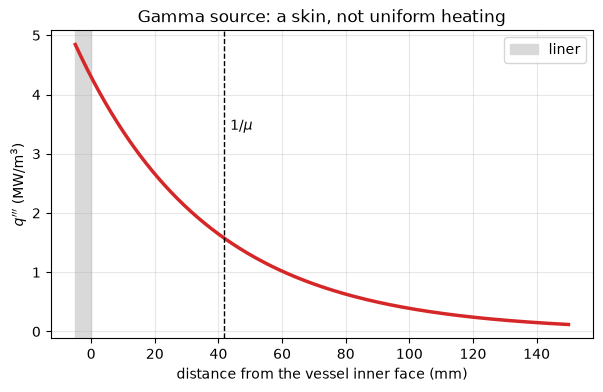

In [84]:
print(f"q0''' = {mu_aus:.0f} x {B_bu} x {flux:.2e} x {E_gamma} x {MeV:.3e} = {q0/1e6:.3f} MW/m3\n")
print(f"source at the wetted surface (R_w = {R_w:.3f} m)        {q0/1e6:7.3f} MW/m3")
print(f"source at the vessel inner face (R_i = {R_i:.3f} m)     {q0*np.exp(-mu_aus*t_lin)/1e6:7.3f} MW/m3"
      f"   (x {np.exp(-mu_aus*t_lin):.3f})")
print(f"source at the vessel outer face (R_o = {R_o:.3f} m)     {q0*np.exp(-mu_aus*t_lin - mu_fer*t_v)/1e6:7.3f} MW/m3")
print(f"\ndecay length 1/mu = {1e3/mu_fer:.1f} mm in a {t_v*1e3:.0f} mm vessel -> mu t = {mu_fer*t_v:.2f}")
print(f"63 % of the energy is deposited in the first {1e3/mu_fer:.0f} mm: the heating is a skin effect.")
print(f"heat generated: {q_gen(q0, t_lin, t_v):.0f} W/m2  (liner {q_gen(q0, t_lin, 0):.0f}, vessel {q_gen(q0, t_lin, t_v) - q_gen(q0, t_lin, 0):.0f})")

xx = np.linspace(0, t_lin + t_v, 500)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot((xx - t_lin)*1e3, q0*np.exp(-mu_aus*xx)/1e6, lw=2.5, color='tab:red')
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner')
ax.axvline(1e3/mu_fer, ls='--', color='k', lw=1); ax.text(1e3/mu_fer + 2, q0/1e6*0.7, r'$1/\mu$')
ax.set_xlabel('distance from the vessel inner face (mm)'); ax.set_ylabel(r"$q'''$ (MW/m$^3$)")
ax.set_title("Gamma source: a skin, not uniform heating"); ax.grid(alpha=0.3); ax.legend(); plt.show()

---
### 5. Item 6: $T(r)$ with and without liner

**Why a liner?** It protects the low-alloy ferritic steel against **corrosion** by the primary water (and limits the release of activable corrosion products). It does **not** protect against heating, on the contrary (see below).

Cases computed:
1. vessel + liner, $h_1$ and $U_2$ (case of item 6);
2. the same vessel **without liner**: its inner face becomes the wetted surface and receives the unattenuated $q_0'''$;
3. vessel + liner with an **adiabatic outer face** ($U_2 = 0$), the assumption behind the Fig. 2 curves.

First the slab (check, energy balance), then the cylindrical solver (reference).

In [85]:
# ---------------- slab ----------------
x_L, T_L, N_L = solve_wall(t_v, t_lin, q0, h1, U2)
x_0, T_0, N_0 = solve_wall(t_v, 0.0,   q0, h1, U2)
S_L, S_0 = summary(x_L, T_L, N_L, t_lin), summary(x_0, T_0, N_0, 0.0)

G = q_gen(q0, t_lin, t_v)
q_in_L, q_out_L = h1*(T_L[0] - T_pr), U2*(T_L[-1] - T_cpp)
print("Energy balance (slab, with liner):")
print(f"  generated {G:9.0f} W/m2 | to the primary {q_in_L:9.0f} ({100*q_in_L/G:.1f} %) | "
      f"to the CPP {q_out_L:7.0f} ({100*q_out_L/G:.1f} %) | closure {100*(q_in_L + q_out_L)/G - 100:+.3f} %")

# ---------------- cylindrical (reference) ----------------
C_L, C_0, C_a = wall_cyl(q0, h1), wall_cyl(q0, h1, liner=False), wall_cyl(q0, h1, U=0.0)
K_L, K_0, K_a = summary_cyl(C_L, R_i), summary_cyl(C_0, R_i), summary_cyl(C_a, R_i)

rows = (("wetted surface (°C)", 'T_w'), ("vessel inner face (°C)", 'T_i'), ("vessel outer face (°C)", 'T_o'),
        ("vessel T_max (°C)", 'T_max'), ("vessel mean (°C)", 'T_avg'))
print(f"\n{'':30}{'cyl no liner':>15}{'cyl liner':>15}{'slab liner':>16}{'slab - cyl':>11}")
for lab, k in rows:
    print(f"{lab:30}{c(K_0[k]):15.1f}{c(K_L[k]):15.1f}{c(S_L[k]):16.1f}{S_L[k] - K_L[k]:+11.1f}")
print(f"{'T_max position (mm from R_i)':30}{K_0['x_max']*1e3:15.1f}{K_L['x_max']*1e3:15.1f}{S_L['x_max']*1e3:16.1f}")
print(f"\nJump across the liner: {K_L['T_i'] - K_L['T_w']:.1f} K over {t_lin*1e3:.0f} mm.")
d_avg, d_max = S_L['T_avg'] - K_L['T_avg'], S_L['T_max'] - K_L['T_max']
print(f"Slab - cylinder: {d_avg:+.1f} K on the mean, {d_max:+.1f} K on the peak -> the slab is "
      f"{'slightly conservative' if min(d_avg, d_max) >= 0 else 'NON-conservative'} here.\n"
      "The reference remains the cylindrical solver (confirmed by Z3ST, item 6).")

# ---------------- DeltaT of the outer film, a posteriori ----------------
q_R2 = C_L['q_out']*R_o/R_2
dT_real = q_R2/h2
print(f"\nCheck of item 4: flux at the insulation outer face {q_R2:.0f} W/m2 -> film dT = {dT_real:.1f} K "
      f"(30 K assumed); U2({dT_real:.0f} K) = {U2_of(h2_of(dT_real)[0]):.3f} vs {U2:.3f} W/(m2 K): no effect.")

Energy balance (slab, with liner):
  generated    196960 W/m2 | to the primary    187080 (95.0 %) | to the CPP    9632 (4.9 %) | closure -0.126 %

                                 cyl no liner      cyl liner      slab liner slab - cyl
wetted surface (°C)                     239.2          239.2           239.0       -0.2
vessel inner face (°C)                  239.2          283.1           282.7       -0.5
vessel outer face (°C)                  396.1          415.5           416.9       +1.4
vessel T_max (°C)                       402.0          422.6           423.8       +1.1
vessel mean (°C)                        372.9          398.2           398.7       +0.5
T_max position (mm from R_i)            108.1          103.2           104.6

Jump across the liner: 44.0 K over 5 mm.
Slab - cylinder: +0.5 K on the mean, +1.1 K on the peak -> the slab is slightly conservative here.
The reference remains the cylindrical solver (confirmed by Z3ST, item 6).

Check of item 4: flux at the ins

**Hand check of the slab (G4 §6).** $T_w = T_{pr} + q''_w/h_1$, then jump across the liner with an almost linearly decreasing flux ($\mu t_L = 0.12 \ll 1$):
$$T_i - T_w \simeq \left(q''_w - \tfrac{1}{2}q_0'''\,t_L\right)\frac{t_L}{k_L}$$

In [86]:
q_w   = G - q_out_L
T_w_h = T_pr + q_w/h1
T_i_h = T_w_h + (q_w - 0.5*q0*t_lin)*t_lin/k_aus
print(f"by hand:               T_w = {c(T_w_h):.1f} °C   T_i = {c(T_i_h):.1f} °C   (upper bound {c(T_w_h + q_w*t_lin/k_aus):.1f} °C)")
print(f"finite differences:    T_w = {c(S_L['T_w']):.1f} °C   T_i = {c(S_L['T_i']):.1f} °C")

by hand:               T_w = 239.0 °C   T_i = 282.6 °C   (upper bound 285.6 °C)
finite differences:    T_w = 239.0 °C   T_i = 282.7 °C


**Two effects of the liner, in opposite directions**:
- **thermal resistance in series**: the heat of the vessel, which flows back almost entirely to the primary, crosses 5 mm of a steel almost half as conductive ($k = 20.1$ vs $37.8$). The whole vessel profile is lifted by about $q''\,t_L/k_L \approx 44$ K. This effect acts on the **level**;
- **attenuation before the vessel**: the liner absorbs about 11 % of the source ($e^{-0.12} = 0.887$), so the temperature difference across the vessel decreases. This effect acts on the **shape**.

The first one wins: the mean and the peak **rise** with the liner. The wetted surface does not move: it is set by $h_1$ and by the total outgoing flux.

**NB-3122.3.** The liner must be considered in the thermal **and** in the stress analysis, unless it is integrally bonded and 10 % or less of the total thickness. Here $5/155 = 3.2\,\%$: it **could** be neglected. We **keep it in the thermal calculation** because neglecting it (case "without liner") gives a vessel about 25 °C colder on average, which would be **non-conservative** for the design temperature. In the stresses, the liner is given **no strength** for the primary stresses (NB-3122.1), but it is kept, bonded to the vessel, for the secondary and peak stresses (item 9): its differential expansion is a peak stress (Table NB-3217-1).

                             actual U2    adiabatic    diff.
vessel T_max (°C)                422.6        459.5    +36.9
vessel mean (°C)                 398.2        422.8    +24.6
outer face (°C)                  415.5        459.5    +43.9
-> The adiabatic assumption of Fig. 2 is conservative (hotter wall).


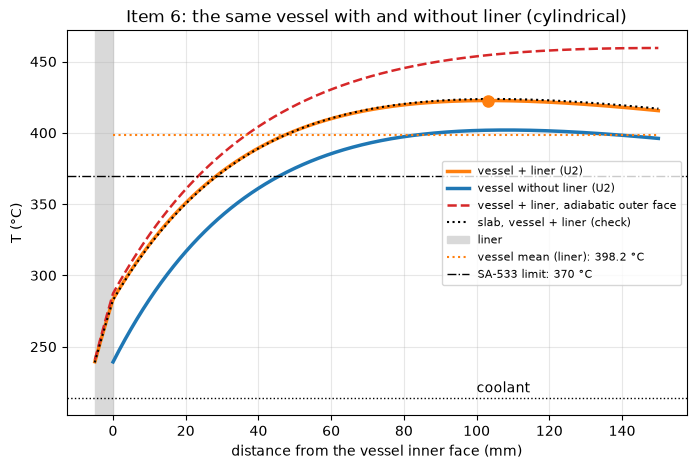

In [87]:
print(f"{'':28}{'actual U2':>10}{'adiabatic':>13}{'diff.':>9}")
for lab, k in (("vessel T_max (°C)", 'T_max'), ("vessel mean (°C)", 'T_avg'), ("outer face (°C)", 'T_o')):
    print(f"{lab:28}{c(K_L[k]):10.1f}{c(K_a[k]):13.1f}{K_a[k] - K_L[k]:+9.1f}")
print("-> The adiabatic assumption of Fig. 2 is conservative (hotter wall).")

xr = lambda sol: (sol['rc'] - R_i)*1e3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xr(C_L), c(C_L['T']), lw=2.5, color='tab:orange', label='vessel + liner (U2)')
ax.plot(xr(C_0), c(C_0['T']), lw=2.5, color='tab:blue', label='vessel without liner (U2)')
ax.plot(xr(C_a), c(C_a['T']), '--', lw=1.8, color='tab:red', label='vessel + liner, adiabatic outer face')
ax.plot((x_L - t_lin)*1e3, c(T_L), ':', lw=1.5, color='k', label='slab, vessel + liner (check)')
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner')
ax.hlines(c(K_L['T_avg']), 0, t_v*1e3, colors='tab:orange', linestyles=':', label=f"vessel mean (liner): {c(K_L['T_avg']):.1f} °C")
ax.plot(K_L['x_max']*1e3, c(K_L['T_max']), 'o', color='tab:orange', ms=8)
ax.axhline(T_lim_fer, color='k', ls='-.', lw=1, label=f'SA-533 limit: {T_lim_fer:.0f} °C')
ax.axhline(c(T_pr), color='k', ls=':', lw=1); ax.text(100, c(T_pr) + 4, 'coolant')
ax.set_xlabel('distance from the vessel inner face (mm)'); ax.set_ylabel('T (°C)')
ax.set_title('Item 6: the same vessel with and without liner (cylindrical)'); ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.show()

#### 5.2 Comparison with Z3ST
Item 6 asks for $T(r)$ **with Z3ST**. Cases: `~/z3st/cuve_liner` and `~/z3st/cuve_sans_liner` (`gmsh mesh.geo -2`, then `python3 -m z3st` from the case folder).

Settings: **both** material cards carry `gamma_heating: 4.845e+6` and `mu_gamma: 24.0`, without `gamma_inner_radius`: Z3ST counts the profile from $R_w$ in both materials. Do **not** put $q_0''' e^{-\mu t_L}$ in the vessel card.

Z3ST deposits the source with the cylindrical profile $K_0(\mu r)/K_0(\mu R_w)$, like our cylindrical solver: we expect agreement within a fraction of a kelvin, and about 1 K with the slab. The cell reads `output/fields.vtu` (`z3st` environment with `pyvista`); otherwise, copy the values into `Z3ST_manual`.

In [88]:
CASES = {'with liner':    (os.path.expanduser('~/z3st/cuve_liner'), K_L, t_lin),
         'without liner': (os.path.expanduser('~/z3st/cuve_sans_liner'), K_0, 0.0)}

# Z3ST values copied by hand (°C) if the automatic reading fails; None = not filled in
Z3ST_manual = {'with liner':    dict(T_max=None, T_avg=None),
               'without liner': dict(T_max=None, T_avg=None)}

def read_z3st(case, t_L):
    import pyvista as pv, yaml
    gm = yaml.safe_load(open(os.path.join(case, 'geometry.yaml')))
    Ri_, Ro_, Lz_ = gm['Ri'], gm['Ro'], gm['Lz']
    line = pv.read(os.path.join(case, 'output', 'fields.vtu')).sample_over_line(
        (Ri_, Lz_/2, 0.0), (Ro_, Lz_/2, 0.0), resolution=2000)
    ok = np.asarray(line['vtkValidPointMask']).astype(bool) & (np.asarray(line['Temperature']) > 1.0)
    r, T = line.points[ok, 0], np.asarray(line['Temperature'])[ok]
    o = np.argsort(r); r, T = r[o], T[o]
    mv = r >= Ri_ + t_L - 1e-9
    return dict(T_w=T[0], T_i=np.interp(Ri_ + t_L, r, T), T_o=T[-1], T_max=T[mv].max(),
                x_max=r[mv][np.argmax(T[mv])] - (Ri_ + t_L),
                T_avg=np.trapezoid(T[mv]*r[mv], r[mv])/np.trapezoid(r[mv], r[mv]))

Z3 = {}
for lab, (case, S, tL) in CASES.items():
    try:
        Z = read_z3st(case, tL)
    except Exception as e:
        m = Z3ST_manual[lab]
        if m['T_max'] is None:
            print(f"[{lab}] Z3ST not read ({type(e).__name__}) and no manual values: comparison skipped.")
            continue
        Z = {k: v + C2K for k, v in m.items() if v is not None}
    Z3[lab] = Z
    print(f"[{lab}]{'':14}{'cyl':>9}{'Z3ST':>9}{'diff.':>8}")
    for k, nm in (('T_w', 'wetted surface'), ('T_i', 'vessel inner face'), ('T_max', 'vessel T_max'), ('T_avg', 'vessel mean')):
        if k in Z:
            print(f"  {nm:24}{c(S[k]):9.1f}{c(Z[k]):9.1f}{Z[k] - S[k]:+8.1f}")

[with liner]                    cyl     Z3ST   diff.
  wetted surface              239.2    239.2    +0.0
  vessel inner face           283.1    283.1    -0.0
  vessel T_max                422.6    422.7    +0.0
  vessel mean                 398.2    398.2    +0.1
[without liner]                    cyl     Z3ST   diff.
  wetted surface              239.2    239.6    +0.4
  vessel inner face           239.2    239.6    +0.4
  vessel T_max                402.0    402.0    +0.0
  vessel mean                 372.9    372.9    +0.1


---
### 6. Item 7: heat flux without source

Without a source, a single heat flux crosses in series the inner film, the liner, the vessel and $U_2$, from the primary (hot) to the CPP. In cylindrical geometry the heat **per unit length** is constant: the flux density at $R_i$ equals the one at $R_o$ multiplied by $R_o/R_i$.

Slab check: $q'' = (T_{pr} - T_{cpp})/(1/h_1 + t_L/k_L + t/k + 1/U_2)$.

Sign: without source the heat **enters** through the inner face; with the source, **both** faces release heat. In Z3ST: copy `cuve_liner` to `cuve_sans_source` with `gamma_heating: 0.0` in both cards.

Without source (cylindrical):
  vessel inner face (R_i):   3.900 kW/m2 outwards
  vessel outer face (R_o):   3.547 kW/m2 to the CPP
  ratio 1.0997 = R_o/R_i = 1.0997 ; slab by hand: 3.567 kW/m2

With source (cylindrical):
  vessel inner face (R_i):   165.5 kW/m2 to the primary
  vessel outer face (R_o):    9.59 kW/m2 to the CPP

Vessel mean: 204.9 °C without source, 398.2 °C with source.


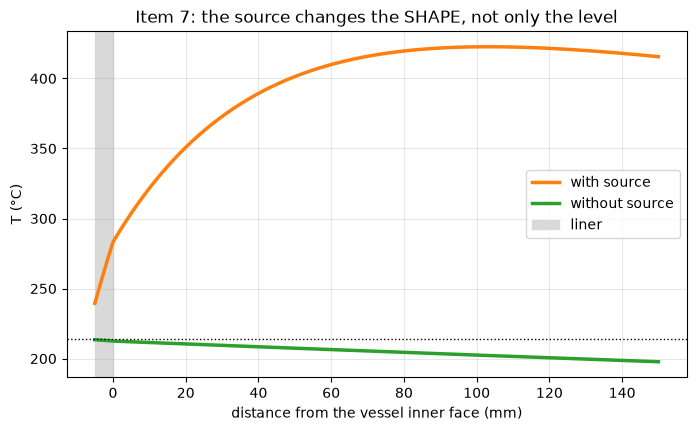

In [89]:
C_n = wall_cyl(0.0, h1); K_n = summary_cyl(C_n, R_i)

def flux_at_Ri(sol):
    # conductive flux density at R_i (W/m2), > 0 = inwards
    lin = sol['rc'] < R_i
    Q_liner = np.sum(sol['q'][lin]*sol['rc'][lin]*sol['dr'][lin])     # generated in the liner, per radian
    return (sol['q_in']*R_w - Q_liner)/R_i

q_hand = (T_pr - T_cpp)/(1/h1 + t_lin/k_aus + t_v/k_fer + 1/U2)
print("Without source (cylindrical):")
print(f"  vessel inner face (R_i): {-flux_at_Ri(C_n)/1e3:7.3f} kW/m2 outwards")
print(f"  vessel outer face (R_o): {C_n['q_out']/1e3:7.3f} kW/m2 to the CPP")
print(f"  ratio {(-flux_at_Ri(C_n))/C_n['q_out']:.4f} = R_o/R_i = {R_o/R_i:.4f} ; slab by hand: {q_hand/1e3:.3f} kW/m2")
print("\nWith source (cylindrical):")
print(f"  vessel inner face (R_i): {flux_at_Ri(C_L)/1e3:7.1f} kW/m2 to the primary")
print(f"  vessel outer face (R_o): {C_L['q_out']/1e3:7.2f} kW/m2 to the CPP")
print(f"\nVessel mean: {c(K_n['T_avg']):.1f} °C without source, {c(K_L['T_avg']):.1f} °C with source.")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xr(C_L), c(C_L['T']), lw=2.5, color='tab:orange', label='with source')
ax.plot(xr(C_n), c(C_n['T']), lw=2.5, color='tab:green', label='without source')
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner'); ax.axhline(c(T_pr), color='k', ls=':', lw=1)
ax.set_xlabel('distance from the vessel inner face (mm)'); ax.set_ylabel('T (°C)')
ax.set_title("Item 7: the source changes the SHAPE, not only the level"); ax.grid(alpha=0.3); ax.legend(); plt.show()

---
### 7. Item 8: closing the design conditions

**NCA-2142.1(b)**, through **NB-3112.2(a)**: the design temperature is not less than the maximum *mean metal temperature through the thickness*; **NB-3112.2(c)**: the internal heat generation (gammas) is taken into account. It is the **mean** (the peak goes to the stresses and to the material limit), a **metal** temperature, in **normal operation**.

Reference: Z3ST if read, otherwise the cylindrical solver. Then:
1. $S_m$ at this temperature, internal pressure (NB-3324.1 / NB-3221);
2. external pressure (NB-3133): $A$ depends only on the geometry; $B$ is read again on CS-5 **at the design temperature** — the highest CS-5 curve is at **345 °C**;
3. peak and mean against the material limit (370 °C for SA-533, 425 °C for 304L).

In [90]:
T_design = c(Z3['with liner']['T_avg']) if 'with liner' in Z3 else c(K_L['T_avg'])
T_peak   = c(Z3['with liner']['T_max']) if 'with liner' in Z3 else c(K_L['T_max'])
T_peak_liner = C_L['T'][C_L['rc'] < R_i].max()
src = 'Z3ST' if 'with liner' in Z3 else 'cylindrical'
print(f"design temperature (vessel mean, with liner, {src}): {T_design:.1f} °C ; peak: {T_peak:.1f} °C")

print("\n--- internal pressure (NB-3324.1) ---")
for lab, T in (("tentative", T_tentative), ("design", T_design)):
    print(f"  {lab:11}{T:6.1f} °C -> row {T_rows[row_of(T)]:.0f}, Sm = {Sm_of(T):5.1f} MPa"
          f" -> t_min = {t_min_int(Sm_of(T))*1e3:5.1f} mm")
print(f"  {t_v*1e3:.0f} mm >= {t_min_int(Sm_of(T_design))*1e3:.1f} mm -> OK")

T_max_CS5 = 345.0     # °C, highest CS-5 curve (Fig. 4)
B_req = 3*(p_D_ext/1e6)*Do_t/4
print("\n--- external pressure (NB-3133) ---")
print(f"  B required for 150 mm: B >= 3 p_D,ext (D_o/t)/4 = {B_req:.1f} MPa")
if T_design > T_max_CS5:
    print(f"  T_design = {T_design:.1f} °C > highest CS-5 curve ({T_max_CS5:.0f} °C): B cannot be read,")
    print("  the material is not covered at this temperature (consistent with the exceedance below).")

print("\n--- temperature limits (NB-1120, NB-3112.4) ---")
for lab, T, lim in (("vessel peak", T_peak, T_lim_fer), ("design (mean)", T_design, T_lim_fer),
                    ("liner peak", c(T_peak_liner), T_lim_aus)):
    print(f"  {lab:18}{T:6.1f} °C vs {lim:.0f} °C -> {'OK' if T <= lim else '*** EXCEEDED ***'}")

design temperature (vessel mean, with liner, Z3ST): 398.2 °C ; peak: 422.7 °C

--- internal pressure (NB-3324.1) ---
  tentative   292.0 °C -> row 300, Sm = 183.3 MPa -> t_min =  69.1 mm
  design      398.2 °C -> row 400, Sm = 182.7 MPa -> t_min =  69.3 mm
  150 mm >= 69.3 mm -> OK

--- external pressure (NB-3133) ---
  B required for 150 mm: B >= 3 p_D,ext (D_o/t)/4 = 125.0 MPa
  T_design = 398.2 °C > highest CS-5 curve (345 °C): B cannot be read,
  the material is not covered at this temperature (consistent with the exceedance below).

--- temperature limits (NB-1120, NB-3112.4) ---
  vessel peak        422.7 °C vs 370 °C -> *** EXCEEDED ***
  design (mean)      398.2 °C vs 370 °C -> *** EXCEEDED ***
  liner peak         283.0 °C vs 425 °C -> OK


In [91]:
# --- the item 8 loop: is a thicker wall colder? ----------------------------------------
for f in (0.90, 1.00, 1.03, 1.10):
    s_ = solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (f*t_v, k_fer, mu_fer)], q0, h1, U2)
    S_ = summary_cyl(s_, R_i)
    print(f"vessel {f*t_v*1e3:5.0f} mm : mean {c(S_['T_avg']):6.1f} °C   peak {c(S_['T_max']):6.1f} °C")
print("\nA thicker wall absorbs more gammas and gets HOTTER: the thickness is not the lever.")
print("The source reaching the wall must be reduced: this is the thermal shield of Part 3.")

vessel   135 mm : mean  391.7 °C   peak  416.7 °C
vessel   150 mm : mean  398.2 °C   peak  422.6 °C
vessel   154 mm : mean  399.8 °C   peak  424.1 °C
vessel   165 mm : mean  403.1 °C   peak  426.9 °C

A thicker wall absorbs more gammas and gets HOTTER: the thickness is not the lever.
The source reaching the wall must be reduced: this is the thermal shield of Part 3.


**Conclusion of item 8.** The design temperature (mean through the lined vessel) is about 398 °C and the peak about 423 °C: both exceed the 370 °C limit of SA-533 Gr. B Cl. 1, above which NB-3112.4 forbids its use. Under internal pressure the 150 mm wall holds easily ($t_{min} \approx 70$ mm); under external pressure, CS-5 does not go beyond 345 °C. Thickening makes things worse: **the design does not close without a thermal shield (Part 3).**

---
### 8. Item 9: Level A verification (NB-3222)

**Actual** metal temperature (NB-3112.2(a)), not the design temperature.

**Pressure loading.** In normal operation the vessel has **75 bar on both sides** (the CPP is at the same pressure): $\sigma_r = \sigma_\theta = \sigma_z = -p$, hydrostatic state, **zero stress intensity**. The pressure therefore contributes neither to $P_m$ nor to $P+Q$; only the thermal gradient matters.

**Preliminary estimate (Fig. 2)**, vessel alone ($a = R_i$, $b = R_o$), with and without the attenuation of the liner:
$$\sigma = \sigma^T\,\frac{\alpha E\,q_0'''}{k\,(1-\nu)\,\mu^2}$$
Fig. 2 assumes an **adiabatic** outer face and gives the **total maximum** thermal stress (peak included). This is not the quantity that NB-3222.2 compares with $3S_m$: it is an **upper bound**.

**Linearised calculation** on the actual cylindrical field ($U_2$): $P_m+P_b+Q$ (membrane + bending) $\le 3S_m$, with $3S_m$ taken as the mean of $S_m$ at the high and low temperatures of the cycle (NB-3222.2); low temperature assumed 40 °C (cold shutdown).

**Liner bonded to the vessel (NB-3122.3).** The stresses are also computed on a **two-layer cylinder** (liner + vessel, bonded, generalised plane strain, closed ends, $T_{ref} = T_{pr}$), the same model as the reference of the instructor's G5 case:
- $P+Q$ of the vessel: two-layer cylinder with the liner given the vessel $\alpha$ (no mismatch), linearised over the vessel;
- total $P+Q+F$: two-layer cylinder with the real $\alpha$ of each material; the difference is the stress from the **differential expansion** ($\alpha_{aus} > \alpha_{fer}$), a **peak stress F** (Table NB-3217-1, NB-3213.11);
- liner: total $P+Q+F$ for the fatigue evaluation (austenitic curve) only. The liner is ≤ 10 % of the thickness: NB-3122.3 exempts it from the $3S_m$ check.

The vessel-alone calculation (`level_A`) is kept for $P_m$ (NB-3122.1) and for comparison.

In [92]:
a_, b_ = R_i, R_o
mu_a, b_a = mu_fer*a_, b_/a_
sigT = 0.67      # Fig. 2 reading at mu*a ≈ 36 and b/a ≈ 1.10 (interpolated between the 30 and 40 curves)
print(f"Fig. 2 : mu a = {mu_a:.1f}, b/a = {b_a:.3f} -> sigma_T = {sigT}")

def Sm_cycle(T_hot):
    T_hot = min(T_hot, T_rows[-1])            # above 425 °C: outside the table
    return 0.5*(Sm_of(T_hot) + Sm_of(40.0))
three_Sm = 3*Sm_cycle(c(K_L['T_max']))

for lab, qv in (("without liner attenuation", q0), ("with liner attenuation", q0*np.exp(-mu_aus*t_lin))):
    sQ = sigT*alpha_fer*E_fer*qv/(k_fer*(1 - nu_fer)*mu_fer**2)/1e6
    print(f"  {lab:28} sigma_max ≈ {sQ:6.0f} MPa (upper bound, adiabatic total peak)")

Pm, PQ, tot = level_A(C_L, a_, b_, E_fer, alpha_fer, nu_fer, p_op, p_op)
print(f"\nActual cylindrical field, vessel + liner, p = {p_op/1e6:.1f} MPa on both sides:")
print(f"  Pm (pressure only)       = {Pm:6.1f} MPa   (hydrostatic -> 0)")
print(f"  Pm + Pb + Q (linearised) = {PQ:6.1f} MPa   vs 3Sm = {three_Sm:.0f} MPa -> {'OK' if PQ <= three_Sm else 'NOT OK'}")
print(f"  total peak (P + Q + F)   = {tot:6.1f} MPa   (for fatigue, NB-3222.4)")
print(f"\nBut T_max = {c(K_L['T_max']):.0f} °C > 370 °C: the Level A verification is meaningless while the material"
      "\nis outside its range (NB-3112.4). The result only shows that stresses are not the problem.")

Fig. 2 : mu a = 36.1, b/a = 1.100 -> sigma_T = 0.67
  without liner attenuation    sigma_max ≈    580 MPa (upper bound, adiabatic total peak)
  with liner attenuation       sigma_max ≈    515 MPa (upper bound, adiabatic total peak)

Actual cylindrical field, vessel + liner, p = 7.5 MPa on both sides:
  Pm (pressure only)       =    0.0 MPa   (hydrostatic -> 0)
  Pm + Pb + Q (linearised) =  194.1 MPa   vs 3Sm = 542 MPa -> OK
  total peak (P + Q + F)   =  447.3 MPa   (for fatigue, NB-3222.4)

But T_max = 423 °C > 370 °C: the Level A verification is meaningless while the material
is outside its range (NB-3112.4). The result only shows that stresses are not the problem.


**Why the two estimates differ**: Fig. 2 gives the point maximum of the thermal stress with an adiabatic outer face (hotter wall, steeper gradient); the linearised calculation removes the non-linear part (peak $F$, which concerns fatigue) and uses the actual $U_2$. The first is a conservative upper bound, the second is the code quantity.

**With Z3ST** (requested by the assignment): full thermo-mechanical calculation of the `cuve_liner` case, with 7.5 MPa applied **on both faces**, compared with $P+Q$ above (next cell).

Item 9, vessel, Level A (MPa)
  'alone' = vessel alone (liner neglected, NB-3122.1) ; 'ref' = same model as Z3ST (with liner: two-layer cylinder, bonded, real alphas)
case            P+Q alone   P+Q ref  P+Q Z3ST  Z3ST-ref   tot ref  tot Z3ST       eps0
with liner          194.1     208.7     207.5     -0.6%     431.1     429.1  2.757e-03
without liner       233.9     233.9     232.4     -0.6%     520.0     514.6  2.426e-03

3Sm = 542 MPa -> with liner OK, without liner OK
  with liner    membrane (r, θ, z) =   -2.2,  -22.1,  -19.2   bending =   -5.8, -193.3, -195.8 MPa
  without liner membrane (r, θ, z) =   -2.0,   -6.9,   -3.8   bending =   -5.7, -233.2, -235.2 MPa


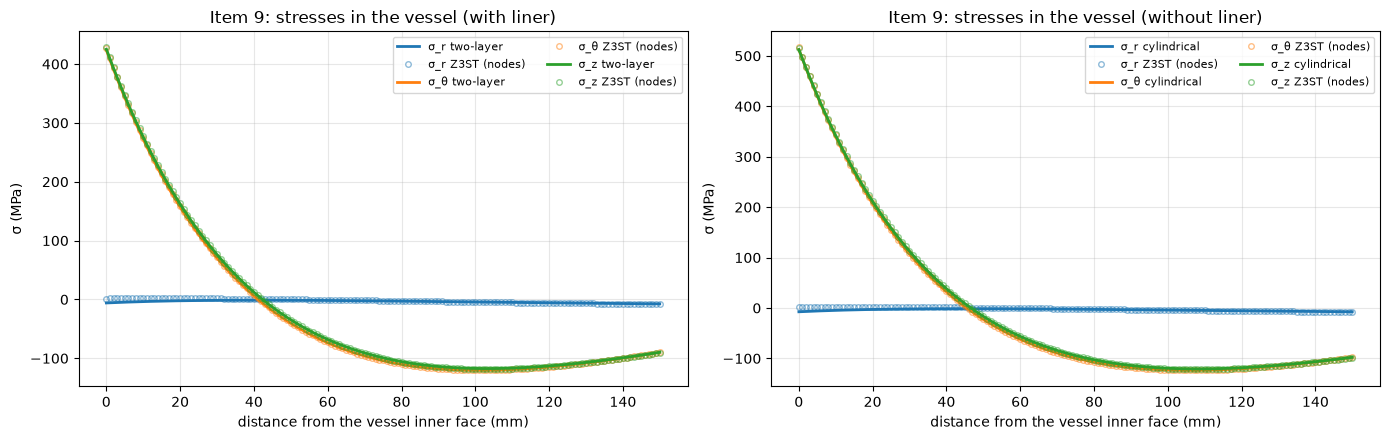

In [113]:
# ===== Item 9: post-processing of the thermo-mechanical Z3ST cases (~/z3st/nudet/*_meca) =====
# Same post-processing as compare_stress.py:
# Z3ST runs in plane strain (eps_z = 0); a uniform eps0 is superposed to recover
# a long, free, closed-end tube (F = p pi Rw^2 - p pi Ro^2), then the vessel is linearised.
import yaml
import pyvista as pv

Z3ST_NUDET = os.path.expanduser('~/z3st/nudet')
CASES_MECA = {'with liner':    ('cuve_liner_meca',      C_L),
              'without liner': ('cuve_sans_liner_meca', C_0)}

def read_z3st_meca(case, p=p_op):
    d = os.path.join(Z3ST_NUDET, case)
    Y = lambda n: yaml.safe_load(open(os.path.join(d, n)))
    g, inp, geo = pv.read(os.path.join(d, 'output', 'fields.vtu')), Y('input.yaml'), Y('geometry.yaml')
    mats = {n: Y(f) for n, f in inp['materials'].items()}; st = mats['steel']
    Rw, Ro, Lz = geo['inner_radius'], geo['outer_radius'], geo['Lz']
    Ri = geo.get('interface_radius', Rw)                     # liner/vessel interface (= Rw without liner)
    ln = g.sample_over_line((Rw, Lz/2, 0), (Ro, Lz/2, 0), resolution=3000)
    ok = np.asarray(ln['vtkValidPointMask']).astype(bool)
    r, S = ln.points[ok, 0], np.asarray(ln['Stress (points)'])[ok]
    o = np.argsort(r); r, S = r[o], S[o]
    sr, sq, sz = S[:, 0], S[:, 4], S[:, 8]                   # order (r, theta, z)
    sz_ps = sz.copy()                                        # raw, plane strain
    E = np.where(r < Ri, float(mats.get('liner', st)['E']), float(st['E']))
    F = p*np.pi*Rw**2 - p*np.pi*Ro**2                        # end effect, closed ends
    eps0 = (F - np.trapezoid(sz*2*np.pi*r, r))/np.trapezoid(E*2*np.pi*r, r)
    sz = sz + E*eps0                                         # tube free to elongate

    # actual FE values: the nodes of the mesh row at mid-height (no interpolation along r)
    P, SP = g.points, np.asarray(g.point_data['Stress (points)'])
    y_mid = P[np.argmin(np.abs(P[:, 1] - Lz/2)), 1]          # y of the node row closest to Lz/2
    row = np.isclose(P[:, 1], y_mid)
    on = np.argsort(P[row, 0]); rn, Sn = P[row, 0][on], SP[row][on]
    En = np.where(rn < Ri, float(mats.get('liner', st)['E']), float(st['E']))
    nodes = dict(r=rn, sr=Sn[:, 0], sq=Sn[:, 4], sz=Sn[:, 8] + En*eps0)   # same closed-end correction

    v = r >= Ri; t = Ro - Ri; x = r[v] - (Ri + Ro)/2
    lin = lambda f: (np.trapezoid(f[v], r[v])/t, 6/t**2*np.trapezoid(f[v]*x, r[v]))
    L = [lin(f) for f in (sr, sq, sz)]
    PQ = max(_SI([m + s*b for m, b in L]) for s in (1, -1))/1e6
    tot = max(_SI([sr[i], sq[i], sz[i]]) for i in np.where(v)[0])/1e6
    return dict(r=r, Ri=Ri, Ro=Ro, sr=sr, sq=sq, sz=sz, sz_ps=sz_ps, eps0=eps0, PQ=PQ, tot=tot,
                m=[m/1e6 for m, _ in L], b=[b/1e6 for _, b in L], nodes=nodes)

Z3M = {}
for lab, (case, sol) in CASES_MECA.items():
    try:
        Z3M[lab] = read_z3st_meca(case)
    except Exception as e:
        print(f"[{lab}] {case} not read: {type(e).__name__}: {e}")

if Z3M:
    mats_real = [(E_aus, nu_aus, alpha_aus), (E_fer, nu_fer, alpha_fer)]   # liner bonded, real alphas (as in Z3ST)

    def lin_PQ_tot(s, sol):
        # vessel only: linearised P+Q and max point SI, from a stress dict (s_r, s_t, s_z per cell)
        rc, dr = sol['rc'], sol['dr']; v = rc >= R_i; t = R_o - R_i; x = rc[v] - (R_i + R_o)/2
        L = [(np.sum(f[v]*dr[v])/t, 6/t**2*np.sum(f[v]*x*dr[v])) for f in (s['s_r'], s['s_t'], s['s_z'])]
        PQ = max(_SI([m + sg*b for m, b in L]) for sg in (1, -1))
        tot = max(_SI([s['s_r'][i], s['s_t'][i], s['s_z'][i]]) for i in np.where(v)[0])
        return PQ/1e6, tot/1e6

    rows, REF = [], {}
    for lab, (case, sol) in CASES_MECA.items():
        if lab not in Z3M: continue
        Z = Z3M[lab]
        _, PQ_a, tot_a = level_A(sol, R_i, R_o, E_fer, alpha_fer, nu_fer, p_op, p_op)   # vessel alone
        if lab == 'with liner':
            s_ref = composite_cyl(sol, R_i, mats_real, p_op, p_op)                       # same model as Z3ST
            PQ_r, tot_r = lin_PQ_tot(s_ref, sol)
        else:
            s_r_, s_t_, s_z_ = stress_cyl(sol['rc'], sol['T'], sol['dr'], R_i, R_o,
                                          E_fer, alpha_fer, nu_fer, p_op, p_op)          # no liner: vessel alone = Z3ST model
            s_ref = dict(s_r=s_r_, s_t=s_t_, s_z=s_z_); PQ_r, tot_r = PQ_a, tot_a
        REF[lab] = s_ref
        rows.append((lab, PQ_a, PQ_r, Z['PQ'], tot_r, Z['tot'], Z['eps0']))

    print("Item 9, vessel, Level A (MPa)")
    print("  'alone' = vessel alone (liner neglected, NB-3122.1) ; 'ref' = same model as Z3ST "
          "(with liner: two-layer cylinder, bonded, real alphas)")
    print(f"{'case':14}{'P+Q alone':>11}{'P+Q ref':>10}{'P+Q Z3ST':>10}{'Z3ST-ref':>10}{'tot ref':>10}{'tot Z3ST':>10}{'eps0':>11}")
    for lab, pa, pr, pz, tr, tz, e0 in rows:
        print(f"{lab:14}{pa:11.1f}{pr:10.1f}{pz:10.1f}{(pz - pr)/pr*100:+9.1f}%{tr:10.1f}{tz:10.1f}{e0:11.3e}")
    print(f"\n3Sm = {three_Sm:.0f} MPa -> " + ", ".join(f"{lab} {'OK' if pz <= three_Sm else 'NOT OK'}"
                                                 for lab, _, _, pz, *_ in rows))
    for lab, Z in Z3M.items():
        print(f"  {lab:13} membrane (r, θ, z) = " + ", ".join(f"{m:6.1f}" for m in Z['m'])
              + "   bending = " + ", ".join(f"{b:6.1f}" for b in Z['b']) + " MPa")

    # plot: Z3ST nodes (closed-end corrected) vs the reference of the same model, in the vessel
    fig, axs = plt.subplots(1, len(Z3M), figsize=(7*len(Z3M), 4.5), squeeze=False)
    cols = ('tab:blue', 'tab:orange', 'tab:green')
    for ax, (lab, Z) in zip(axs[0], Z3M.items()):
        sol = CASES_MECA[lab][1]; vv = sol['rc'] >= R_i - 1e-12
        ana = (REF[lab]['s_r'][vv], REF[lab]['s_t'][vv], REF[lab]['s_z'][vv])
        N = Z['nodes']
        xa = (sol['rc'][vv] - R_i)*1e3; xn = (N['r'] - Z['Ri'])*1e3; k = xn >= 0   # vessel only
        ref_lab = 'two-layer' if lab == 'with liner' else 'cylindrical'
        for a, s, nm, col in zip(ana, (N['sr'], N['sq'], N['sz']), ('σ_r', 'σ_θ', 'σ_z'), cols):
            ax.plot(xa, a/1e6, color=col, lw=2, label=f'{nm} {ref_lab}')                          # analytic: line
            ax.plot(xn[k], s[k]/1e6, 'o', color=col, mfc='none', ms=4, markevery=2, alpha=0.5,
                    label=f'{nm} Z3ST (nodes)')                                                     # FE: points
        ax.set_title(f"Item 9: stresses in the vessel ({lab})")
        ax.set_xlabel('distance from the vessel inner face (mm)'); ax.set_ylabel('σ (MPa)')
        ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
    plt.tight_layout(); plt.show()

In [94]:
# ===== Item 9: liner bonded (NB-3122.3), differential expansion as peak stress F (Table NB-3217-1) =====
LA = level_A_lined(C_L, p_op, p_op)
print(f"vessel: P+Q (linearised) = {LA['PQ_v']:.1f} MPa (vessel alone: {PQ:.1f}) vs 3Sm = {three_Sm:.0f} MPa ; "
      f"total P+Q+F = {LA['tot_v']:.1f} MPa (vessel alone: {tot:.1f})")
print(f"liner:  total P+Q+F = {LA['tot_L']:.1f} MPa (fatigue, austenitic curve) ; "
      f"of which differential expansion |F| = {LA['F_L']:.1f} MPa")

vessel: P+Q (linearised) = 210.1 MPa (vessel alone: 194.1) vs 3Sm = 542 MPa ; total P+Q+F = 431.1 MPa (vessel alone: 447.3)
liner:  total P+Q+F = 570.2 MPa (fatigue, austenitic curve) ; of which differential expansion |F| = 65.5 MPa


---
## Part 2: verification of the preliminary choices

In [95]:
print(f"vessel T_max = {c(K_L['T_max']):.1f} °C   T_design = {T_design:.1f} °C   limit = {T_lim_fer:.0f} °C (NB-1120)")
print(f"-> T_max - limit = {c(K_L['T_max']) - T_lim_fer:+.0f} K: creep is not a failure mode to be handled with NB (Division 5),")
print("   the material is simply forbidden above 370 °C (NB-3112.4): component NOT admissible without a shield.")

vessel T_max = 422.6 °C   T_design = 398.2 °C   limit = 370 °C (NB-1120)
-> T_max - limit = +53 K: creep is not a failure mode to be handled with NB (Division 5),
   the material is simply forbidden above 370 °C (NB-3112.4): component NOT admissible without a shield.


| Part 0 answer | Status | Comment |
|---|---|---|
| ASME III, Div. 1, Subsection NB | confirmed | Class 1 pressure boundary |
| No creep, time-independent $S_m$ | **not confirmed without shield** | $T_{max} \approx 423$ °C > 370 °C; confirmed with the shield (Part 3) |
| $p_D = 8.25$ MPa (internal) | confirmed | $t_{min} \approx 70$ mm, not governing |
| $p_{D,ext} = 7.55$ MPa (external) | confirmed | governing: 150 mm (minimum 145 mm) |
| Tentative $T_D$ = 292 °C | **to be changed** | 398 °C without shield; 337 °C with the 15 mm shield (Part 3) |

**Item 9**: the Level A stresses are not limiting (linearised $P+Q$ well below $3S_m$, hydrostatic pressure without effect); it is the **temperature** that rules out the design and requires the thermal shield.

---
## Part 3: thermal shield

### 3.1 Material selection criteria
Function: **attenuate the gammas** before the vessel. Criteria: high attenuation coefficient (high density, high $Z$); good thermal **conductivity** (the shield heats up itself: low internal peak); low thermal expansion and good mechanical strength at temperature (thermal stresses); compatibility with the primary water (corrosion, release of activable products); resistance to irradiation; cost and weldability. The assignment imposes SA-533 Gr. B Cl. 1 ($\mu = 24$ m⁻¹).

### 3.2 Classification
The shield is **not** a pressure boundary: Quality Groups A–D do not apply to it. It is a reactor **internal structure** (ASME III, Subsection NG, *internal structure*), **not classified** in the pressure-boundary safety sense, but **Seismic Category I**: its fall or failure could damage the core or block the flow.

### 3.3 Corrosion
**No**, not as the vessel is: the shield is not a pressure boundary and its loss by corrosion does not compromise containment. A **corrosion allowance** is enough to keep its attenuation over the lifetime. (Question 1 of Part 4 deals precisely with the case where it should also be protected.) It is therefore modelled **without liner**.

### Method
The coaxial shield splits the downcomer into **two parallel channels** (barrel–shield, shield–liner); the flow divides so as to equalise the pressure drops:
$$\Delta p_j = \left(f_j\frac{L}{D_{h,j}} + K\right)\frac{\rho u_j^2}{2}, \qquad f_j = 0.184\,\mathrm{Re}_j^{-0.2}, \qquad K = 1.5$$
For the vessel, the shield changes two things: the source at the wetted surface becomes $q_0'''\,e^{-\mu_s t_s}$ (water gap assumed transparent: conservative) and the film coefficient becomes the $h$ of the shield–liner channel.

**Build-up**: $B = 1.4$ is already included in $q_0'''$ (Table 1). It is not applied again in the shield: $\mu$ is given as an effective coefficient, and the build-up depends on the total optical thickness crossed, not on each layer. Applying it again (effective $B \approx 1.4^2 \approx 2$) would count the scattered photons twice; for information, this upper bound would require about 26 mm instead of 13.


vessel T_max (°C)
  R_s \ t_s (mm)       5      10      15      20      25      30      35      40
            1270   396.6   374.3   354.5   337.1   321.7   308.1   296.0   285.4
            1280   396.3   374.1   354.4   337.0   321.6   308.0   295.9   285.3
            1290   396.2   373.9   354.2   336.8   321.4   307.9   295.8   285.2
            1300   396.0   373.8   354.1   336.7   321.3   307.8   295.8   285.2
            1310   395.8   373.6   354.0   336.6   321.2   307.7   295.7   285.1
            1320   395.6   373.4   353.8   336.5   321.1   307.6   295.6   285.0
            1330   395.5   373.3   353.7   336.3   321.0   307.5   295.5   284.9
            1340   395.3   373.1   353.5   336.2   320.9   307.4   295.4   284.9
            1350   395.1   373.0   353.4   336.1   320.8   307.3   295.3   284.8
            1360   394.9   372.8   353.3   336.0   320.7   307.2   295.2   284.7
            1370   394.8   372.7   353.1   335.8   320.6   307.1   295.1   284.6
         

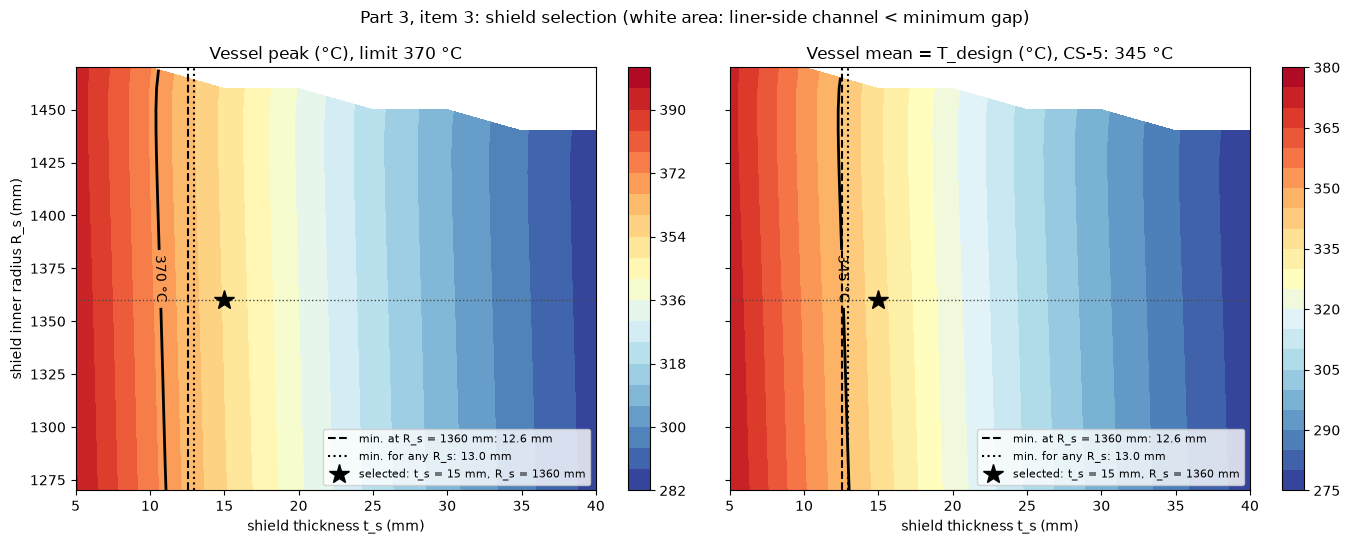

In [96]:
R_bar  = D_be/2
mu_s = mu_fer
K_form = 1.5
gap_min = 0.02            # m, minimum gap of each channel (fabrication, assembly)
t_s, R_s = 0.015, 1.36    # m, selected shield (thickness, inner radius): decided from this sweep

def channel(R_in, R_out, m_ch):
    gap = R_out - R_in; A_ch = np.pi*(R_out**2 - R_in**2)
    Dh = 2*gap
    u = m_ch/(rho_pr*A_ch); Re = rho_pr*u*Dh/eta_pr
    h = 0.023*Re**0.8*Pr_pr**0.4*k_pr/Dh
    f = 0.184*Re**-0.2
    dp = (f*L/Dh + K_form)*rho_pr*u**2/2
    return dict(gap=gap, u=u, Re=Re, h=h, dp=dp, ok_DB=Re > 1e4 and 0.6 < Pr_pr < 160 and L/Dh > 10)

def split(R_s, t_s):
    sh = brentq(lambda s: channel(R_bar, R_s, s*m_dot)['dp'] - channel(R_s + t_s, R_w, (1 - s)*m_dot)['dp'],
                1e-3, 1 - 1e-3)
    return sh, channel(R_bar, R_s, sh*m_dot), channel(R_s + t_s, R_w, (1 - sh)*m_dot)

def with_shield(R_s, t_s):
    # the build-up 1.4 of Table 1 is already in q0 and applies at any depth (mu is effective):
    # the shield only attenuates the source, q = q0 e^(-mu t_s)
    sh, ci, co = split(R_s, t_s)
    f = np.exp(-mu_s*t_s)
    sol = wall_cyl(f*q0, co['h'])
    return dict(share=sh, ci=ci, co=co, f=f, sol=sol, S=summary_cyl(sol, R_i))

# ===== Part 3, item 3: sweep of the shield (R_s, t_s) =====
# Criteria: T_max <= 370 °C (NB-3112.4) and T_mean <= 345 °C (highest CS-5 curve, external pressure).
R_s_list = np.round(np.arange(R_bar + gap_min, R_w - gap_min, 0.01), 3)   # m, 1 cm steps, minimum gap on both sides
t_s_list = np.arange(5, 41, 5)*1e-3                                        # m

SW = {}
for R_s_ in R_s_list:
    for t_ in t_s_list:
        if R_s_ + t_ > R_w - gap_min: continue           # liner-side channel too narrow
        W1 = with_shield(R_s_, t_)
        SW[R_s_, t_] = dict(Tmax=c(W1['S']['T_max']), Tavg=c(W1['S']['T_avg']),
                            h=W1['co']['h'], dp=W1['co']['dp'])

for nom, cle in (("vessel T_max (°C)", 'Tmax'), ("vessel T_mean (°C)", 'Tavg')):
    print(f"\n{nom}\n{'R_s \\ t_s (mm)':>16}" + "".join(f"{t_*1e3:8.0f}" for t_ in t_s_list))
    for R_s_ in R_s_list:
        print(f"{R_s_*1e3:16.0f}" + "".join(f"{SW[R_s_, t_][cle]:8.1f}" if (R_s_, t_) in SW else f"{'-':>8}"
                                         for t_ in t_s_list))

# minimum thickness per criterion: at the selected R_s, and for any R_s (barrel side and middle of the downcomer)
R_mid = round((R_bar + R_w)/2, 2)
t_min_at = lambda R_, k_, lim: brentq(lambda t: c(with_shield(R_, t)['S'][k_]) - lim, 1e-3, R_w - gap_min - R_)
crit = (("T_max <= 370 °C", 'T_max', T_lim_fer), ("T_mean <= 345 °C", 'T_avg', 345.0))
t_min_sel = {k_: t_min_at(R_s, k_, lim) for _, k_, lim in crit}
t_min_all = {k_: max(t_min_at(R_, k_, lim) for R_ in (R_s_list[0], R_mid)) for _, k_, lim in crit}
print(f"\nMinimum shield thickness (mm):{'at R_s = ' + f'{R_s*1e3:.0f} mm':>20}{'any R_s':>11}")
for nom, k_, _ in crit:
    print(f"  {nom:28}{t_min_sel[k_]*1e3:20.1f}{t_min_all[k_]*1e3:11.1f}")
t_s_min_sel, t_s_min_all = max(t_min_sel.values()), max(t_min_all.values())
print(f"-> governing: {t_s_min_sel*1e3:.1f} mm at the selected R_s, {t_s_min_all*1e3:.1f} mm for any R_s "
      f"({'mean' if t_min_sel['T_avg'] > t_min_sel['T_max'] else 'peak'} governs) ; selected t_s = {t_s*1e3:.0f} mm")

# maps (t_s, R_s): colours = vessel temperature, solid line = limit,
# dashed = minimum at the selected R_s, dotted = minimum for any R_s, star = selected shield
ts_mm = t_s_list*1e3; Rs_mm = np.array(R_s_list)*1e3
grid = lambda cle: np.array([[SW[R_, t_][cle] if (R_, t_) in SW else np.nan for t_ in t_s_list] for R_ in R_s_list])
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax_, cle, lim, nom in ((axs[0], 'Tmax', T_lim_fer, 'Vessel peak (°C), limit 370 °C'),
                           (axs[1], 'Tavg', 345.0, 'Vessel mean = T_design (°C), CS-5: 345 °C')):
    cf = ax_.contourf(ts_mm, Rs_mm, grid(cle), levels=20, cmap='RdYlBu_r')
    cs = ax_.contour(ts_mm, Rs_mm, grid(cle), levels=[lim], colors='k', linewidths=2)
    ax_.clabel(cs, fmt=f'{lim:.0f} °C')
    ax_.axvline(t_s_min_sel*1e3, color='k', ls='--', lw=1.5, label=f'min. at R_s = {R_s*1e3:.0f} mm: {t_s_min_sel*1e3:.1f} mm')
    ax_.axvline(t_s_min_all*1e3, color='k', ls=':', lw=1.5, label=f'min. for any R_s: {t_s_min_all*1e3:.1f} mm')
    ax_.axhline(R_s*1e3, color='0.3', ls=':', lw=1)
    ax_.plot(t_s*1e3, R_s*1e3, 'k*', ms=15, label=f'selected: t_s = {t_s*1e3:.0f} mm, R_s = {R_s*1e3:.0f} mm')
    fig.colorbar(cf, ax=ax_)
    ax_.set_title(nom); ax_.set_xlabel('shield thickness t_s (mm)')
    ax_.legend(fontsize=8, loc='lower right')
axs[0].set_ylabel('shield inner radius R_s (mm)')
plt.suptitle('Part 3, item 3: shield selection (white area: liner-side channel < minimum gap)')
plt.tight_layout(); plt.show()

Two temperature limits apply. First, the maximum metal temperature must not exceed 370 °C (NB-3112.4). Second, the design temperature, i.e. the mean through the thickness (NCA-2142.1(b)), must not exceed 345 °C, the highest CS-5 curve: above it, the external-pressure check, which sizes the shell, can no longer be performed. Since the peak exceeds the mean by less than 25 K (about 16 K with the shield), the criterion on the mean temperature governs.

In [97]:
t_s, R_s = 0.015, 1.36
WS = with_shield(R_s, t_s)               # design case: B = 1.4 already in q0
ci, co, K_s = WS['ci'], WS['co'], WS['S']
print(f"shield: R_s = {R_s*1e3:.0f} mm, t_s = {t_s*1e3:.0f} mm ; channels {ci['gap']*1e3:.0f} / {co['gap']*1e3:.0f} mm")
print(f"flow: {100*WS['share']:.1f} % barrel side, {100*(1 - WS['share']):.1f} % liner side ; dp = {ci['dp']/1e3:.2f} kPa")
print(f"h inner channel = {ci['h']:.0f}, h outer channel = {co['h']:.0f} W/(m2 K) ; "
      f"Re = {ci['Re']:.2e} / {co['Re']:.2e} ; Dittus-Boelter {'OK' if ci['ok_DB'] and co['ok_DB'] else 'NOT OK'}")
print(f"vessel (design): peak {c(K_s['T_max']):.1f} °C, mean {c(K_s['T_avg']):.1f} °C -> margins "
      f"{T_lim_fer - c(K_s['T_max']):.0f} K (peak / 370) and {345 - c(K_s['T_avg']):.0f} K (mean / 345)")

shield: R_s = 1360 mm, t_s = 15 mm ; channels 110 / 125 mm
flow: 44.1 % barrel side, 55.9 % liner side ; dp = 2.63 kPa
h inner channel = 9231, h outer channel = 9087 W/(m2 K) ; Re = 2.76e+06 / 3.17e+06 ; Dittus-Boelter OK
vessel (design): peak 353.3 °C, mean 336.9 °C -> margins 17 K (peak / 370) and 8 K (mean / 345)


### 3.4 Temperature profile in the shield
Slab (as requested), source $q_0'''\,e^{-\mu x}$ from the inner face (the flux impinges on the shield), Dittus-Boelter on each face with the flow rate of each channel, both fluids at $T_{pr}$.

heat generated in the shield: 61.0 kW/m2 ; to the inner channel 31.5, to the outer channel 29.1 kW/m2
inner face 217.4 °C | outer face 217.2 °C | max 220.3 °C at 7.1 mm from the inner face | mean 219.3 °C


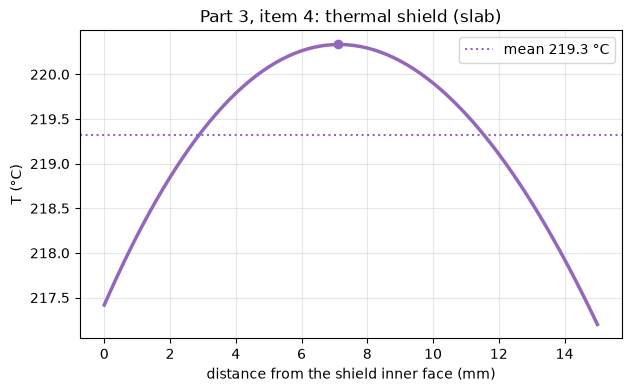

In [98]:
xs, Ts, _ = solve_wall(t_s, 0.0, q0, ci['h'], co['h'], T_in=T_pr, T_out=T_pr)
i_m = int(np.argmax(Ts)); Ts_avg = np.trapezoid(Ts, xs)/t_s
Gs = q0/mu_s*(1 - np.exp(-mu_s*t_s))
print(f"heat generated in the shield: {Gs/1e3:.1f} kW/m2 ; to the inner channel {ci['h']*(Ts[0] - T_pr)/1e3:.1f}, "
      f"to the outer channel {co['h']*(Ts[-1] - T_pr)/1e3:.1f} kW/m2")
print(f"inner face {c(Ts[0]):.1f} °C | outer face {c(Ts[-1]):.1f} °C | max {c(Ts[i_m]):.1f} °C at {xs[i_m]*1e3:.1f} mm "
      f"from the inner face | mean {c(Ts_avg):.1f} °C")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs*1e3, c(Ts), lw=2.5, color='tab:purple'); ax.plot(xs[i_m]*1e3, c(Ts[i_m]), 'o', color='tab:purple')
ax.axhline(c(Ts_avg), ls=':', color='tab:purple', label=f'mean {c(Ts_avg):.1f} °C')
ax.set_xlabel('distance from the shield inner face (mm)'); ax.set_ylabel('T (°C)')
ax.set_title('Part 3, item 4: thermal shield (slab)'); ax.grid(alpha=0.3); ax.legend(); plt.show()

### 3.5 Design conditions of the shield
- **Pressure**: both channels start from the same plenum and end in the same plenum; the pressure difference across the shield is of the order of the channel pressure drop (a few kPa). The absolute pressure (75 bar) acts on both faces: hydrostatic state, no deviatoric stress. A lump **differential design pressure** of 0.1 MPa is taken, which largely covers $\Delta p$ and flow transients.
- **Temperature**: maximum mean through the thickness, rounded up.

In [99]:
dp_design_sh = 0.1e6
T_design_sh = np.ceil(c(Ts_avg)/5)*5
print(f"shield: dp_design = {dp_design_sh/1e6:.1f} MPa (actual dp {ci['dp']/1e3:.1f} kPa), T_design = {T_design_sh:.0f} °C, "
      f"peak {c(Ts.max()):.0f} °C vs limit {T_lim_fer:.0f} °C -> {'OK' if c(Ts.max()) <= T_lim_fer else 'NOT OK'}")

shield: dp_design = 0.1 MPa (actual dp 2.6 kPa), T_design = 220 °C, peak 220 °C vs limit 370 °C -> OK


### 3.6 Stresses in the shield (Level A)
Cylinder $R_s$ – $R_s + t_s$, 75 bar on both faces (hydrostatic, no effect), thermal stresses only.

In [100]:
C_sh = solve_cyl(R_s, [(t_s, k_fer, mu_s)], q0, ci['h'], co['h'], T_in=T_pr, T_out=T_pr)
Pm_s, PQ_s, tot_s = level_A(C_sh, R_s, R_s + t_s, E_fer, alpha_fer, nu_fer, p_op, p_op)
three_Sm_s = 3*Sm_cycle(c(C_sh['T'].max()))
print(f"Pm = {Pm_s:.1f} MPa | Pm+Pb+Q = {PQ_s:.1f} MPa vs 3Sm = {three_Sm_s:.0f} MPa -> "
      f"{'OK' if PQ_s <= three_Sm_s else 'NOT OK'} | total peak {tot_s:.1f} MPa")

Pm = 0.0 MPa | Pm+Pb+Q = 0.8 MPa vs 3Sm = 550 MPa -> OK | total peak 8.2 MPa


### 3.7 Effect of the shield inner radius (qualitative, with numbers)
- Small $R_s$ (close to the barrel): narrow inner channel, little flow; wide, slow outer channel, lower $h$ on the vessel. The shield receives a higher gamma flux (closer to the core) and has a smaller area (less material for the same thickness).
- Large $R_s$ (close to the liner): narrow outer channel, higher $h$ on the vessel, but too small a gap is sensitive to tolerances, vibrations and blockage risk; more material (larger radius).
- The vessel temperature depends very little on $R_s$ (the source seen by the vessel depends only on $t_s$); $R_s$ mainly affects the flow split, the $h$ values and the space constraints.

In [101]:
print(f"{'R_s mm':>7}{'channel in/out mm':>18}{'flow in %':>12}{'h out':>8}{'vessel peak °C':>16}{'shield peak °C':>16}")
for Rs_ in (1.28, 1.32, 1.36, 1.40, 1.44):
    w = with_shield(Rs_, t_s)
    _, Tsh, _ = solve_wall(t_s, 0.0, q0, w['ci']['h'], w['co']['h'], T_in=T_pr, T_out=T_pr)
    print(f"{Rs_*1e3:7.0f}{w['ci']['gap']*1e3:9.0f}/{w['co']['gap']*1e3:<8.0f}{100*w['share']:12.1f}{w['co']['h']:8.0f}"
          f"{c(w['S']['T_max']):16.1f}{c(Tsh.max()):16.1f}")

 R_s mm channel in/out mm   flow in %   h out  vessel peak °C  shield peak °C
   1280       30/205              8.9    8377           354.4           220.4
   1320       70/165             26.0    8717           353.8           220.3
   1360      110/125             44.1    9087           353.3           220.3
   1400      150/85              62.9    9513           352.7           220.3
   1440      190/45              82.3    9863           352.2           220.3


### 3.8 Items 5, 6, 8 and 9 of Part 1 with the shield

Shield: t_s = 15 mm, R_s = 1360 mm ; transmission e^(-mu t_s) = 0.698

Item 5: gamma source (MW/m3)
                                no shield          shield
wetted surface                     4.8415          3.3778
vessel inner face                  4.2895          2.9927
vessel outer face                  0.1119          0.0780

Item 6: vessel temperatures (°C)
                                  no shield          shield
wetted surface                        239.2           228.4
vessel inner face                     283.1           258.8
vessel outer face                     415.5           347.0
vessel T_max                          422.6           353.3
vessel mean                           398.2           336.9
T_max position (mm from R_i)          103.2            99.2

Item 8: T_design = 336.9 °C (no shield: 398.2 °C ; item 2: 292 °C tentative)
  peak 353.3 °C <= 370 °C (NB-3112.4) and mean 336.9 °C <= 345 °C (CS-5) -> OK ; margins 17 K and 8 K
  internal (NB-3324.1): row 350 °C

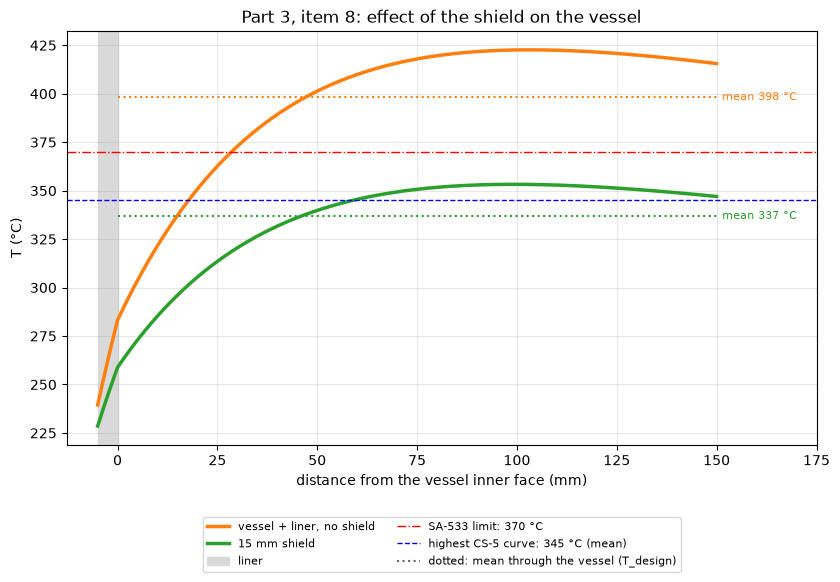

In [102]:
# ===== Part 3, item 8: items 5, 6, 8 and 9 of Part 1 repeated with the shield =====
# Design case: q0 already contains B = 1.4 (Table 1), applied at any depth, shield included:
#   q(d) = 1.4 mu phi E e^(-mu d) = q0 e^(-mu d)  ->  with_shield(R_s, t_s)
WS  = with_shield(R_s, t_s)            # build-up 1.4 of the assignment, already in q0
C_S, K_s = WS['sol'], WS['S']

def q_faces(sol):
    # volumetric source (MW/m3) at the wetted surface, vessel inner face and vessel outer face (solver profile, K0)
    rc, q = sol['rc'], sol['q']
    return q[0]/1e6, np.interp(R_i, rc, q)/1e6, q[-1]/1e6

# ---------------- item 5: gamma source ----------------
print(f"Shield: t_s = {t_s*1e3:.0f} mm, R_s = {R_s*1e3:.0f} mm ; transmission e^(-mu t_s) = {WS['f']:.3f}")
print("\nItem 5: gamma source (MW/m3)")
print(f"{'':26}{'no shield':>15}{'shield':>16}")
for lab, j in (("wetted surface", 0), ("vessel inner face", 1), ("vessel outer face", 2)):
    print(f"{lab:26}{q_faces(C_L)[j]:15.4f}{q_faces(C_S)[j]:16.4f}")

# ---------------- item 6: temperature profile ----------------
print("\nItem 6: vessel temperatures (°C)")
print(f"{'':28}{'no shield':>15}{'shield':>16}")
for lab, k in (("wetted surface", 'T_w'), ("vessel inner face", 'T_i'), ("vessel outer face", 'T_o'),
               ("vessel T_max", 'T_max'), ("vessel mean", 'T_avg')):
    print(f"{lab:28}{c(K_L[k]):15.1f}{c(K_s[k]):16.1f}")
print(f"{'T_max position (mm from R_i)':28}{K_L['x_max']*1e3:15.1f}{K_s['x_max']*1e3:16.1f}")

# ---------------- item 8: design conditions ----------------
T_design_S = c(K_s['T_avg']); T_peak_S = c(K_s['T_max'])
ok_T = T_peak_S <= T_lim_fer and T_design_S <= T_CS5_max
print(f"\nItem 8: T_design = {T_design_S:.1f} °C (no shield: {c(K_L['T_avg']):.1f} °C ; item 2: 292 °C tentative)")
print(f"  peak {T_peak_S:.1f} °C <= {T_lim_fer:.0f} °C (NB-3112.4) and mean {T_design_S:.1f} °C <= {T_CS5_max:.0f} °C (CS-5)"
      f" -> {'OK' if ok_T else 'NOT OK'} ; margins {T_lim_fer - T_peak_S:.0f} K and {T_CS5_max - T_design_S:.0f} K")
Sm_S = Sm_of(T_design_S); t_int_S = t_min_int(Sm_S)
print(f"  internal (NB-3324.1): row {T_rows[row_of(T_design_S)]:.0f} °C, Sm = {Sm_S:.1f} MPa -> t_min = "
      f"{t_int_S*1e3:.1f} mm <= {t_v*1e3:.0f} mm -> {'OK' if t_int_S <= t_v else 'NOT OK'}")
B_TD = B_CS5(A_chart, T_design_S)
print(f"  external (NB-3133):  A = {A_chart:.2e} (geometry, unchanged) ; B({T_design_S:.0f} °C) = {B_TD:.1f} MPa (CS-5 table)"
      f" vs {B_req:.1f} MPa required -> {'OK' if B_TD >= B_req else 'NOT OK'} (margin {100*(B_TD/B_req - 1):+.1f} %)")

# ---------------- item 9: Level A ----------------
q_vi = q_faces(C_S)[1]*1e6                                  # source at the vessel inner face
sQ_S = sigT*alpha_fer*E_fer*q_vi/(k_fer*(1 - nu_fer)*mu_fer**2)/1e6
Pm_S, PQ_S, tot_S = level_A(C_S, R_i, R_o, E_fer, alpha_fer, nu_fer, p_op, p_op)
three_Sm_S = 3*Sm_cycle(T_peak_S)
print(f"\nItem 9: Level A (NB-3222), p = {p_op/1e6:.1f} MPa on both sides")
print(f"  Fig. 2 (upper bound, adiabatic peak): {sQ_S:.0f} MPa")
print(f"  Pm (pressure only)       = {Pm_S:6.1f} MPa")
print(f"  Pm + Pb + Q (linearised) = {PQ_S:6.1f} MPa vs 3Sm = {three_Sm_S:.0f} MPa -> {'OK' if PQ_S <= three_Sm_S else 'NOT OK'}"
      f"   (no shield: {PQ:.1f} MPa)")
print(f"  total peak P + Q + F     = {tot_S:6.1f} MPa (fatigue, NB-3222.4)")

# ---------------- figure ----------------
fig, ax = plt.subplots(figsize=(8.5, 6))
for sol_, S_, col_, ls_, lw_, lab_ in ((C_L, K_L, 'tab:orange', '-', 2.5, 'vessel + liner, no shield'),
                                       (C_S, K_s, 'tab:green', '-', 2.5, f'{t_s*1e3:.0f} mm shield')):
    ax.plot(xr(sol_), c(sol_['T']), lw=lw_, ls=ls_, color=col_, label=lab_)
    # mean through the vessel (= T_design), drawn over the vessel thickness only
    ax.hlines(c(S_['T_avg']), 0, t_v*1e3, colors=col_, linestyles=':', lw=1.5)
    ax.annotate(f"mean {c(S_['T_avg']):.0f} °C", (t_v*1e3, c(S_['T_avg'])), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=8, color=col_)
ax.axvspan(-t_lin*1e3, 0, color='0.85', label='liner')
ax.axhline(T_lim_fer, color='red', ls='-.', lw=1, label='SA-533 limit: 370 °C')
ax.axhline(T_CS5_max, color='blue', ls='--', lw=1, label='highest CS-5 curve: 345 °C (mean)')
ax.set_xlabel('distance from the vessel inner face (mm)'); ax.set_ylabel('T (°C)')
ax.plot([], [], ls=':', color='0.4', label='dotted: mean through the vessel (T_design)')
ax.set_xlim(right=t_v*1e3 + 25)
ax.set_title('Part 3, item 8: effect of the shield on the vessel'); ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2); plt.tight_layout()
plt.show()

In [103]:
# ===== Item 8: NB-3221.1, internal design pressure =====
# NB-3324 only gives a tentative thickness: Pm <= Sm(T_D) must be checked (Lamé, vessel alone, NB-3122.1)
for lab, sol, TD in (("no shield", C_L, T_design), ("15 mm shield", C_S, T_design_S)):
    Pm_D, _, _ = level_A(sol, R_i, R_o, E_fer, alpha_fer, nu_fer, p_D, 0.0)   # p_D inside, CPP lost
    Sm_D = Sm_of(TD)
    note = "" if TD <= T_lim_fer else "  (T_D > 370 °C: material not qualified, NB-3112.4)"
    print(f"{lab:13} T_D = {TD:5.1f} °C  Pm = {Pm_D:5.1f} MPa vs Sm = {Sm_D:5.1f} MPa -> "
          f"{'OK' if Pm_D <= Sm_D else 'NOT OK'} (margin {100*(Sm_D/Pm_D - 1):+.0f} %){note}")
print("NB-3221.3: Pb = 0 away from discontinuities -> Pm + Pb = Pm <= 1.5 Sm, satisfied as well.")

no shield     T_D = 398.2 °C  Pm =  86.7 MPa vs Sm = 182.7 MPa -> OK (margin +111 %)  (T_D > 370 °C: material not qualified, NB-3112.4)
15 mm shield  T_D = 336.9 °C  Pm =  86.7 MPa vs Sm = 183.3 MPa -> OK (margin +111 %)
NB-3221.3: Pb = 0 away from discontinuities -> Pm + Pb = Pm <= 1.5 Sm, satisfied as well.


**Conclusion of Part 3.** With the 15 mm shield, the vessel peak drops to about 353 °C (17 K below 370 °C) and the design temperature to about 337 °C (8 K below the highest CS-5 curve). Under internal pressure, $t_{min} \approx 69$ mm. Under external pressure, $B$ at 337 °C is 126.2 MPa against 125.0 MPa required for 150 mm: **150 mm is kept**, with a margin of about 1 %. The Level A stresses of the vessel ($P+Q \approx 127$ MPa vs $3S_m = 550$ MPa) and of the shield are admissible.

In [104]:
# ===== Part 3: 13 mm shield (minimum thickness, design model B = 1.4 in q0) =====
# Then re-sizing of the vessel under external pressure (NB-3133): T_D, A and B depend on the thickness.
t_s13, R_s13 = 0.013, 1.36            # m ; R_s has no effect on the vessel, same value as the Z3ST cases
W13 = with_shield(R_s13, t_s13)       # design: B = 1.4 already in q0
f13, h13 = W13['f'], W13['co']['h']
print(f"Shield {t_s13*1e3:.0f} mm: transmission e^(-mu t_s) = {f13:.3f}, source at the wetted surface "
      f"{f13*q0/1e6:.3f} MW/m3, h liner-side channel = {h13:.0f} W/m2K")

# A(t): power law on the Fig. G readings of 'tab' (Part 1, item 3b), function A_of; beyond 150 mm: extrapolated
print(f"\nExternal pressure, {t_s13*1e3:.0f} mm shield, p_D,ext = {p_D_ext/1e6:.2f} MPa")
print(f"{'t vessel':>9}{'T_D °C':>9}{'peak °C':>9}{'D_o/t':>8}{'A':>10}{'B MPa':>8}{'P_a MPa':>9}{'margin':>8}  verdict")
rows13 = []
for tv_mm in range(140, 171, 5):
    tv = tv_mm*1e-3
    sol_ = solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (tv, k_fer, mu_fer)], f13*q0, h13, U2)
    S_ = summary_cyl(sol_, R_i)
    TD, Tpk = c(S_['T_avg']), c(S_['T_max'])
    Do_ = 2*(R_i + tv); Dot = Do_/tv; A_ = A_of(tv_mm)
    if TD <= 345.0:
        B_ = B_CS5(A_, TD); Pa = 4*B_/(3*Dot); m = Pa*1e6/p_D_ext - 1
        ok = Pa*1e6 >= p_D_ext and Tpk <= T_lim_fer
        verdict = 'OK' if ok else 'NOT OK'
    else:
        B_ = Pa = m = np.nan; ok = False; verdict = 'T_D > 345 °C: outside CS-5'
    rows13.append(dict(t=tv_mm, TD=TD, Tpk=Tpk, A=A_, B=B_, Pa=Pa, ok=ok))
    print(f"{tv_mm:9d}{TD:9.1f}{Tpk:9.1f}{Dot:8.2f}{A_:10.2e}{B_:8.1f}{Pa:9.3f}{100*m:+7.1f}%  {verdict}"
          + ("   (A extrapolated)" if tv_mm > 150 else ""))

ok13 = [r['t'] for r in rows13 if r['ok']]
print(f"\n-> admissible vessel thicknesses with the {t_s13*1e3:.0f} mm shield: "
      + (", ".join(f"{t} mm" for t in ok13) if ok13 else "none in the range"))
print("   A thicker vessel has a larger A (better resistance) but absorbs more gammas: T_D rises")
print("   towards 345 °C, where B drops and then can no longer be read. The design is squeezed between the two.")
r150 = next(r for r in rows13 if r['t'] == 150)
print(f"\n150 mm vessel: T_D = {r150['TD']:.1f} °C (margin {345 - r150['TD']:.1f} K on CS-5), "
      f"P_a = {r150['Pa']:.3f} MPa (margin {100*(r150['Pa']*1e6/p_D_ext - 1):+.1f} %)")
print(f"   internal: Sm({r150['TD']:.0f} °C) = {Sm_of(r150['TD']):.1f} MPa -> t_min = {t_min_int(Sm_of(r150['TD']))*1e3:.1f} mm -> OK")

Shield 13 mm: transmission e^(-mu t_s) = 0.732, source at the wetted surface 3.546 MW/m3, h liner-side channel = 9001 W/m2K

External pressure, 13 mm shield, p_D,ext = 7.55 MPa
 t vessel   T_D °C  peak °C   D_o/t         A   B MPa  P_a MPa  margin  verdict
      140    340.6    358.2   23.50  4.54e-03   124.8    7.080   -6.2%  NOT OK
      145    342.1    359.5   22.76  4.78e-03   125.3    7.339   -2.8%  NOT OK
      150    343.5    360.8   22.07  5.03e-03   125.8    7.599   +0.6%  OK
      155    344.8    361.9   21.42  5.28e-03   126.2    7.858   +4.1%  OK   (A extrapolated)
      160    345.9    362.9   20.81  5.53e-03     nan      nan   +nan%  T_D > 345 °C: outside CS-5   (A extrapolated)
      165    346.9    363.8   20.24  5.79e-03     nan      nan   +nan%  T_D > 345 °C: outside CS-5   (A extrapolated)
      170    347.9    364.6   19.71  6.05e-03     nan      nan   +nan%  T_D > 345 °C: outside CS-5   (A extrapolated)

-> admissible vessel thicknesses with the 13 mm shield: 150 m

With the minimum shield thickness (13 mm), the vessel is admissible only from 150 to 155 mm, with at best 1.5 K of margin on the CS-5 reading limit and 0.6 % on the allowable external pressure: a thicker vessel raises T_D above 345 °C, a thinner one does not withstand the pressure. A shield thicker than the minimum is therefore selected.


=== 13 mm shield: transmission 0.732, source at the wetted surface 3.546 MW/m3, h liner side 9001 W/m2K ; p_D,ext = 7.55 MPa
 t vessel   T_D °C  peak °C   D_o/t         A   B MPa  P_a MPa  P_a margin  T_D margin  verdict
      140    340.6    358.2   23.50  4.54e-03   124.8    7.080       -6.2%      +4.4 K  NOT OK
      145    342.1    359.5   22.76  4.78e-03   125.3    7.339       -2.8%      +2.9 K  NOT OK
      150    343.5    360.8   22.07  5.03e-03   125.8    7.599       +0.6%      +1.5 K  OK
      155    344.8    361.9   21.42  5.28e-03   126.2    7.858       +4.1%      +0.2 K  OK   (A extrapolated)
      160    345.9    362.9   20.81  5.53e-03     nan      nan       +nan%      -0.9 K  outside CS-5 (T_D > 345 °C)   (A extrapolated)
      165    346.9    363.8   20.24  5.79e-03     nan      nan       +nan%      -1.9 K  outside CS-5 (T_D > 345 °C)   (A extrapolated)
      170    347.9    364.6   19.71  6.05e-03     nan      nan       +nan%      -2.9 K  outside CS-5 (T_D > 345 °C)  

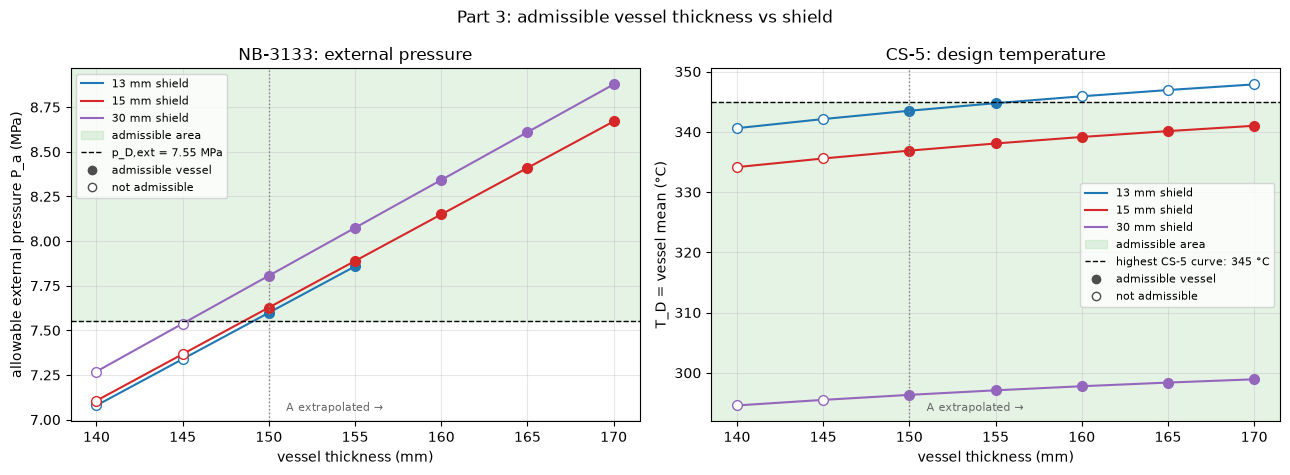

In [105]:
# ===== Part 3: vessel thickness under external pressure (NB-3133) vs shield thickness =====
# Design model: B = 1.4 already in q0. For each shield and each vessel thickness:
# T_D (mean) and peak from the thermal model, A (Fig. G, geometry), B (CS-5 table at T_D), P_a = 4B/(3 D_o/t).
def balayage_cuve(t_sh, R_sh=1.36, tv_list=range(140, 171, 5)):
    # A(t): function A_of (power law on the Fig. G readings, Part 1 item 3b); > 150 mm: extrapolated
    W = with_shield(R_sh, t_sh)
    out = []
    for tv_mm in tv_list:
        tv = tv_mm*1e-3
        S = summary_cyl(solve_cyl(R_w, [(t_lin, k_aus, mu_aus), (tv, k_fer, mu_fer)], W['f']*q0, W['co']['h'], U2), R_i)
        TD, Tpk = c(S['T_avg']), c(S['T_max'])
        Dot = 2*(R_i + tv)/tv; A = A_of(tv_mm)
        B = B_CS5(A, TD) if TD <= 345.0 else np.nan
        Pa = 4*B/(3*Dot)
        ok = bool(TD <= 345.0 and Tpk <= T_lim_fer and Pa*1e6 >= p_D_ext)
        out.append(dict(tv=tv_mm, TD=TD, Tpk=Tpk, Dot=Dot, A=A, B=B, Pa=Pa, mPa=100*(Pa*1e6/p_D_ext - 1),
                        mT=345.0 - TD, ok=ok))
    return W, out

BOUCLIERS = (0.013, 0.015, 0.030)            # m, add other shield thicknesses if needed (0.020, ...)
RES = {}
for t_sh in BOUCLIERS:
    W, rows_ = balayage_cuve(t_sh)
    RES[t_sh] = rows_
    print(f"\n=== {t_sh*1e3:.0f} mm shield: transmission {W['f']:.3f}, source at the wetted surface {W['f']*q0/1e6:.3f} MW/m3, "
          f"h liner side {W['co']['h']:.0f} W/m2K ; p_D,ext = {p_D_ext/1e6:.2f} MPa")
    print(f"{'t vessel':>9}{'T_D °C':>9}{'peak °C':>9}{'D_o/t':>8}{'A':>10}{'B MPa':>8}{'P_a MPa':>9}{'P_a margin':>12}"
          f"{'T_D margin':>12}  verdict")
    for r in rows_:
        verdict = 'OK' if r['ok'] else ('outside CS-5 (T_D > 345 °C)' if r['TD'] > 345 else 'NOT OK')
        print(f"{r['tv']:9d}{r['TD']:9.1f}{r['Tpk']:9.1f}{r['Dot']:8.2f}{r['A']:10.2e}{r['B']:8.1f}{r['Pa']:9.3f}"
              f"{r['mPa']:+11.1f}%{r['mT']:+10.1f} K  {verdict}" + ("   (A extrapolated)" if r['tv'] > 150 else ""))
    oks = [r['tv'] for r in rows_ if r['ok']]
    print(f"-> admissible vessels: " + (f"{min(oks)} to {max(oks)} mm" if oks else "none in the range"))

# --- summary at 150 mm ---
print(f"\nSummary, 150 mm vessel:")
print(f"{'shield':>10}{'T_D °C':>9}{'T_D margin':>12}{'P_a MPa':>9}{'P_a margin':>12}")
for t_sh, rows_ in RES.items():
    r = next(r for r in rows_ if r['tv'] == 150)
    print(f"{t_sh*1e3:8.0f} mm{r['TD']:9.1f}{r['mT']:+10.1f} K{r['Pa']:9.3f}{r['mPa']:+11.1f}%")

# --- figure: both criteria vs vessel thickness, one colour per shield ---
# green area = admissible side of the criterion; filled marker = admissible vessel (all criteria), hollow = not admissible
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
COLS = ('tab:blue', 'tab:red', 'tab:purple', 'tab:orange', 'tab:brown', 'tab:gray')   # no green: reserved for the areas
for (t_sh, rows_), col in zip(RES.items(), COLS):
    tv_ = np.array([r['tv'] for r in rows_]); ok_ = np.array([r['ok'] for r in rows_])
    axs[0].plot(tv_, [r['Pa'] for r in rows_], '-', color=col, label=f'{t_sh*1e3:.0f} mm shield')
    axs[1].plot(tv_, [r['TD'] for r in rows_], '-', color=col, label=f'{t_sh*1e3:.0f} mm shield')
    for ax_, key in ((axs[0], 'Pa'), (axs[1], 'TD')):
        y_ = np.array([r[key] for r in rows_])
        ax_.plot(tv_[ok_], y_[ok_], 'o', color=col, ms=7)
        ax_.plot(tv_[~ok_], y_[~ok_], 'o', mfc='white', mec=col, ms=7)
for ax_, lim, below, lab in ((axs[0], p_D_ext/1e6, False, f'p_D,ext = {p_D_ext/1e6:.2f} MPa'),
                             (axs[1], 345.0, True, 'highest CS-5 curve: 345 °C')):
    ax_.relim(); ax_.autoscale_view(); y0, y1 = ax_.get_ylim()
    ax_.axhspan(y0 if below else lim, lim if below else y1, color='tab:green', alpha=0.12, zorder=0, label='admissible area')
    ax_.axhline(lim, color='k', ls='--', lw=1, label=lab); ax_.set_ylim(y0, y1)
    ax_.axvline(150, color='0.5', ls=':', lw=1)
    ax_.text(151, y0 + 0.03*(y1 - y0), 'A extrapolated →', fontsize=8, color='0.4')
    ax_.set_xlabel('vessel thickness (mm)'); ax_.grid(alpha=0.3)
    ax_.plot([], [], 'o', color='0.3', label='admissible vessel'); ax_.plot([], [], 'o', mfc='white', mec='0.3', label='not admissible')
    ax_.legend(fontsize=8)
axs[0].set_ylabel('allowable external pressure P_a (MPa)'); axs[0].set_title('NB-3133: external pressure')
axs[1].set_ylabel('T_D = vessel mean (°C)'); axs[1].set_title('CS-5: design temperature')
plt.suptitle('Part 3: admissible vessel thickness vs shield'); plt.tight_layout(); plt.show()

With the 15 mm shield, the design temperature drops from about 398 °C to about 337 °C. The external pressure, which governs the thickness, depends on the temperature only through B, which varies by only about 3 % between 290 and 345 °C. The vessel thickness therefore does **not** change: with the 15 mm shield, 145 mm fails (−2.4 %) and 150 mm passes (+1.0 %). 150 mm is kept; the margin on the external pressure is thin, and a 155 mm vessel would bring it to about +4.5 %.

In [106]:
LA_S = level_A_lined(C_S, p_op, p_op)
print(f"vessel (shield): P+Q = {LA_S['PQ_v']:.1f} MPa (vessel alone {PQ_S:.1f}) vs 3Sm = {three_Sm_S:.0f} ; total = {LA_S['tot_v']:.1f} MPa")
print(f"liner (shield):  total = {LA_S['tot_L']:.1f} MPa (fatigue) ; differential expansion |F| = {LA_S['F_L']:.1f} MPa")

vessel (shield): P+Q = 138.2 MPa (vessel alone 127.2) vs 3Sm = 550 ; total = 292.6 MPa
liner (shield):  total = 391.8 MPa (fatigue) ; differential expansion |F| = 42.5 MPa


In [107]:
# G2 checklist: how far NB-3324.1 is from Lamé at our t/a (a = R_w, NB-3122.2(a))
def lame(r, a, b, p):
    A = p*a**2/(b**2 - a**2); return A*(1 - b**2/r**2), A*(1 + b**2/r**2)
for lab, t in (("NB-3324.1 thickness", t_min_int(Sm_of(T_tentative))), ("carried wall", t_v)):
    a, b, p = R_w, R_w + t, p_D
    _, st = lame(np.array([a]), a, b, p); hM = p*a/t; nb = hM + p/2
    print(f"{lab:20} t = {t*1e3:5.1f} mm, t/a = {t/a:.3f}: Lame peak {st[0]/1e6:6.1f} MPa | p a/t {hM/1e6:6.1f} "
          f"({100*(st[0]/hM - 1):+.1f} %) | p a/t + p/2 {nb/1e6:6.1f} ({100*(st[0]/nb - 1):+.1f} %)")

NB-3324.1 thickness  t =  69.1 mm, t/a = 0.046: Lame peak  183.4 MPa | p a/t  179.2 (+2.4 %) | p a/t + p/2  183.3 (+0.1 %)
carried wall         t = 150.0 mm, t/a = 0.100: Lame peak   86.8 MPa | p a/t   82.5 (+5.2 %) | p a/t + p/2   86.6 (+0.2 %)


---
## Appendix: Z3ST figures

Figures produced by Z3ST (`check.py`, `compare_stress.py`) in `~/z3st/nudet/<case>/output/`, grouped by item. The numerical comparisons are at items 6 (temperature), 9 (stresses) and in Part 3 (shield).

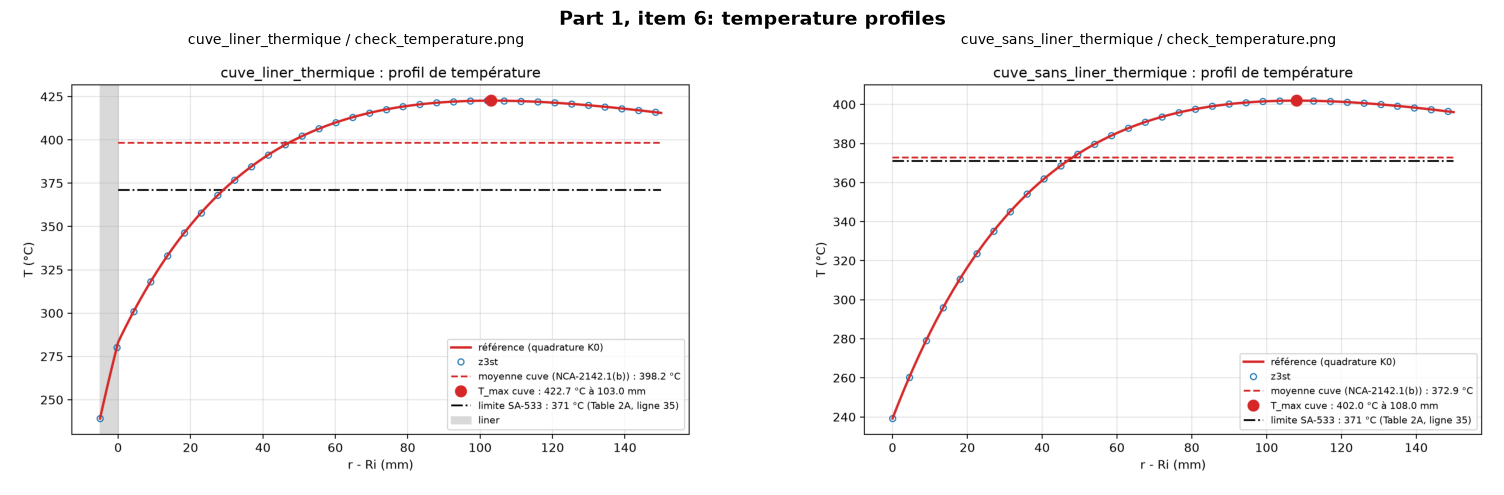

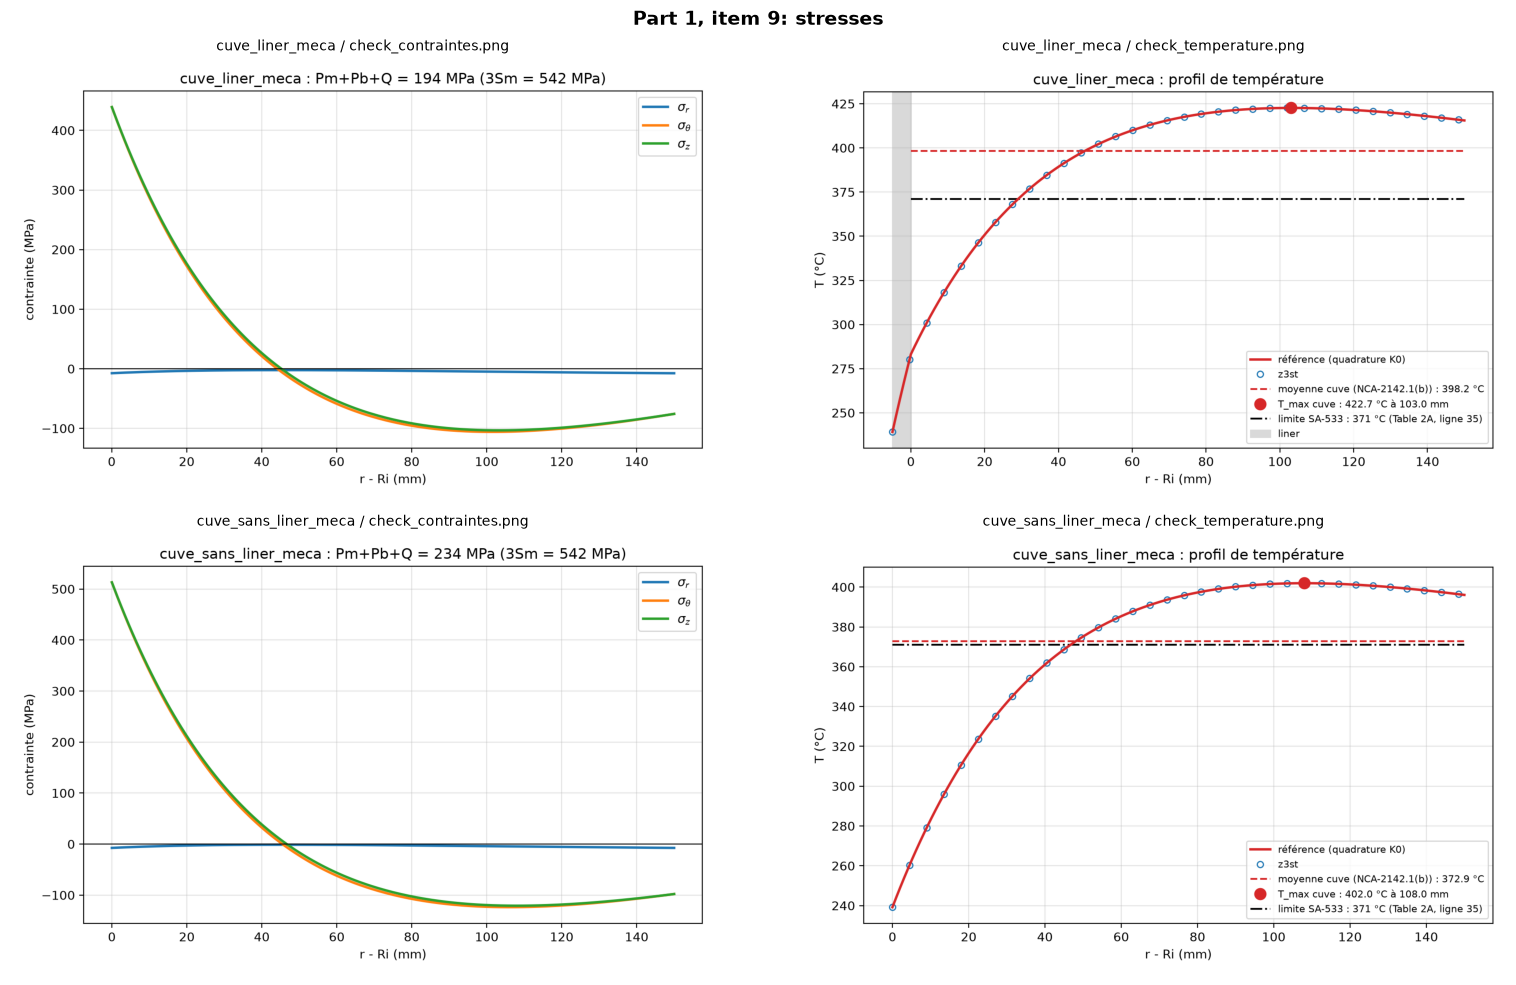

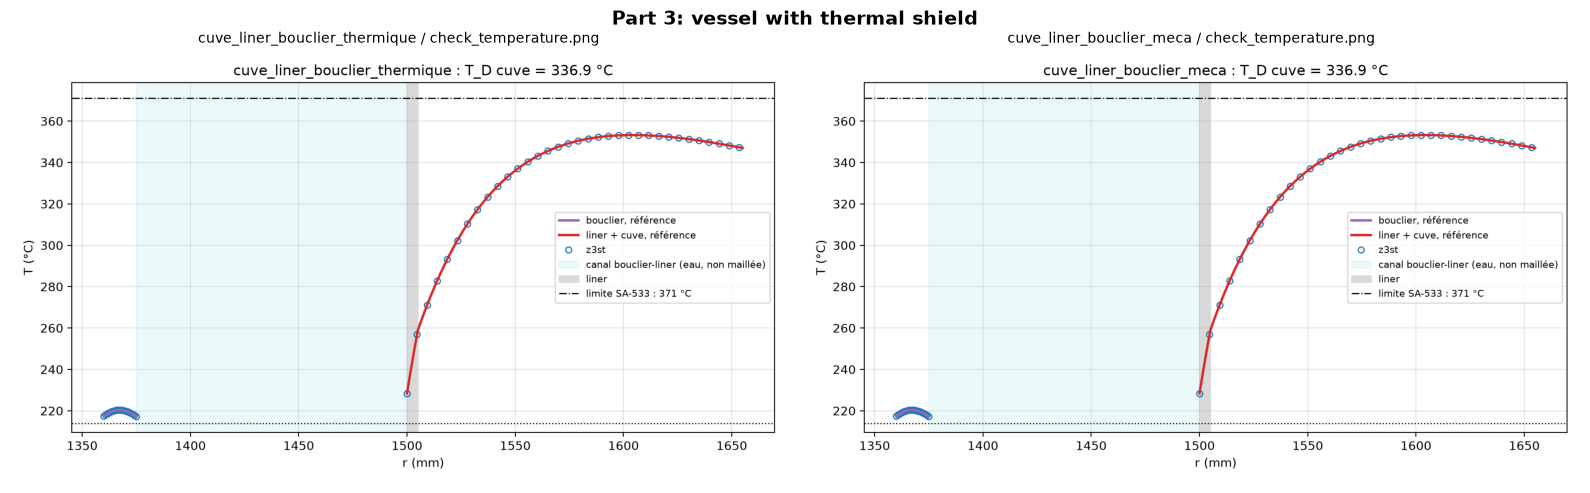

In [108]:
# ===== Appendix: figures produced by Z3ST (check.py / compare_stress.py) =====
import glob
import matplotlib.image as mpimg

Z3ST_NUDET = os.path.expanduser('~/z3st/nudet')
GROUPES = [
    ("Part 1, item 6: temperature profiles", ['cuve_liner_thermique', 'cuve_sans_liner_thermique']),
    ("Part 1, item 9: stresses",             ['cuve_liner_meca', 'cuve_sans_liner_meca']),
    ("Part 3: vessel with thermal shield",   ['cuve_liner_bouclier_thermique', 'cuve_liner_bouclier_meca']),
]

for titre, cas in GROUPES:
    figs = [(c_, f) for c_ in cas for f in sorted(glob.glob(os.path.join(Z3ST_NUDET, c_, 'output', '*.png')))]
    if not figs:
        print(f"{titre}: no figure found in {', '.join(cas)}"); continue
    n = len(figs); nc = min(n, 2); nr = -(-n//nc)
    fig, axs = plt.subplots(nr, nc, figsize=(8*nc, 5*nr), squeeze=False)
    for ax in axs.flat: ax.axis('off')
    for ax, (c_, f) in zip(axs.flat, figs):
        ax.imshow(mpimg.imread(f))
        ax.set_title(f"{c_} / {os.path.basename(f)}", fontsize=10)
    fig.suptitle(titre, fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()